# Claim-type analysis: schema boundaries across models

**Goal:** establish the boundaries of each claim type, test whether the extracted structure is invariant across models, and probe a candidate **POSITIONING** type.

**Data:** `outputs/claims_analysis/claims_all.csv` (one row per statement) and `claims_exclusions.csv`, built by `scripts/build_claims_csv.py` from every valid argument map in `outputs/` plus the gold maps in `tests/fixtures/gold/`. Rebuild with:

```
.venv\Scripts\python.exe scripts\build_claims_csv.py
```

| Group | Columns |
|---|---|
| Run | `run_id`, `source_family`, `variant`, `doc`, `model`, `taxonomy_version`, `run_*` (from `summary.json`) |
| Document | `doc_title`, `doc_publisher`, `doc_publication_date`, `doc_authors`, ... |
| Statement | `statement_id`, `brief`, `statement`, `claim_type`, `modality`, `modality_cue`, `evidence_texts`, `evidence_in_source` |
| Argument | `is_core`, `is_isolated`, `role_set`, `roles`, `argument_summaries`, `argument_core_types` |
| Alignment | `gold_match_id` / `gold_claim_type` (ING, MS, Ocado); `cluster_id` / `cluster_pivot_claim_type` (all docs; SundayTea pivots on `new_rules_v2/SundayTea/opus`) |
| Gold only | `gold_rejected_links`, `gold_adjudication_notes` (filtered to the statement) |

Probes below are **regex heuristics** that estimate how often a field *could* be filled from the text; they are not extractions. VIEW and OBSERVATION have no dedicated section but appear in the overview, boundary checks and the POSITIONING probe.

## 0. Setup

In [ ]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "outputs" / "claims_analysis"
JSON_COLUMNS = [
    "evidence_ids", "evidence_texts", "roles", "argument_ids", "argument_summaries", "argument_core_types",
    "doc_authors", "doc_asset_classes", "gold_rejected_links", "gold_adjudication_notes",
]
TYPES = ["RECOMMENDATION", "VALUATION", "FORECAST", "POSITIONING", "VIEW", "DATA_POINT", "OBSERVATION"]
MODELS = ["haiku", "sonnet", "opus", "gold"]


def _parse_json(value):
    return json.loads(value) if isinstance(value, str) and value else []


all_claims = pd.read_csv(DATA_DIR / "claims_all.csv", encoding="utf-8-sig")
for col in JSON_COLUMNS:
    all_claims[col] = all_claims[col].map(_parse_json)
all_claims["evidence"] = all_claims["evidence_texts"].map(" | ".join)
all_claims["text"] = all_claims["statement"] + " || " + all_claims["evidence"]
exclusions = pd.read_csv(DATA_DIR / "claims_exclusions.csv", encoding="utf-8-sig")

# None = every run. SundayTea dominates (ablations + comparisons); ["new_rules_v2", "gold"] gives one run per doc and model.
SCOPE = None
claims = all_claims if SCOPE is None else all_claims[all_claims["source_family"].isin(SCOPE)].copy()

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 200)
print(f"{len(claims)} statements from {claims['run_id'].nunique()} runs")
claims.groupby(["source_family", "doc", "model"]).size().unstack("model", fill_value=0)

2374 statements from 44 runs


model                                     gold  haiku  opus  sonnet
source_family                  doc                                 
ablation                       SundayTea     0    364   140     218
gold                           ING          40      0     0       0
                               MS           14      0     0       0
                               Ocado        26      0     0       0
new_rules                      ING           0     59    63      32
                               MS            0     32    26      19
                               Ocado         0     40    35      16
                               SundayTea     0    111    99      40
new_rules_v2                   ING           0     60    59      36
                               MS            0     35    27      23
                               Ocado         0     45    37      17
                               SundayTea     0    112    95      63
sunday_tea_model_comparison    SundayTea     0     93    83      22
sunday_tea_model_comparison_v2 SundayTea     0     86    70      37

In [2]:
SHOW = ["run_id", "statement_id", "claim_type", "modality", "modality_cue", "statement"]


def of_type(claim_type, df=None):
    df = claims if df is None else df
    return df[df["claim_type"] == claim_type]


def probe(df, patterns, col="statement"):
    """One boolean column per named regex (case-insensitive) matched against ``col``."""
    return pd.DataFrame(
        {name: df[col].str.contains(p, case=False, regex=True, na=False) for name, p in patterns.items()},
        index=df.index,
    )


def fill_rates(df, patterns, by="model", col="statement"):
    """Share of rows matching each probe, per group (fields as rows)."""
    return probe(df, patterns, col).groupby(df[by]).mean().round(2).T


def first_match(df, patterns, col="statement"):
    """Per row, the first text matched by each probe: a preview of what the field would hold."""
    return pd.DataFrame(
        {name: df[col].str.extract(f"({p})", flags=re.IGNORECASE)[0] for name, p in patterns.items()}, index=df.index
    )


def by_model(df, col):
    """Row-normalised distribution of ``col`` per model."""
    table = pd.crosstab(df["model"], df[col], normalize="index").round(2)
    return table.reindex([m for m in MODELS if m in table.index])


def boundary(claim_type, df=None):
    """Aligned rows in clusters typed ``claim_type`` by at least one run and something else by another."""
    df = claims if df is None else df
    aligned = df.dropna(subset=["cluster_id"])
    clusters = aligned.loc[aligned["claim_type"] == claim_type, "cluster_id"].unique()
    sub = aligned[aligned["cluster_id"].isin(clusters)]
    mixed = sub.groupby("cluster_id")["claim_type"].transform("nunique") > 1
    return sub[mixed].sort_values(["cluster_id", "model"])


def boundary_summary(claim_type, df=None):
    """In clusters touched by ``claim_type``: how often each other type was assigned instead."""
    rows = boundary(claim_type, df)
    return rows.loc[rows["claim_type"] != claim_type, "claim_type"].value_counts()


# One row per (statement, argument, role), with the type of that argument's core claim.
memberships = claims[["run_id", "model", "doc", "statement_id", "claim_type", "roles"]].explode("roles")
memberships = memberships.dropna(subset=["roles"]).reset_index(drop=True)
memberships = memberships.assign(
    role=memberships["roles"].map(lambda r: r["role"]),
    argument_id=memberships["roles"].map(lambda r: r["argument_id"]),
    core_type=memberships["roles"].map(lambda r: r["core_type"]),
).drop(columns="roles")

## 1. Overview and model invariance

Questions: do models agree on the *type* of the same statement? Which pairs of types are confused? Is the modality cue a short marker or a long phrase?

In [3]:
pd.crosstab([claims["doc"], claims["model"]], claims["claim_type"]).reindex(columns=TYPES, fill_value=0)

claim_type        RECOMMENDATION  VALUATION  FORECAST  VIEW  DATA_POINT  \
doc       model                                                           
ING       gold                 0          5         8    19           4   
          haiku                0         10        27    51          11   
          opus                 0         10        40    39          14   
          sonnet               0          7        22    27           9   
MS        gold                 2          0         1     6           4   
          haiku                6          0         3    29          15   
          opus                 4          0         3    18          16   
          sonnet               4          0         2    15          14   
Ocado     gold                 1          2         9    11           2   
          haiku                2          9        15    36          10   
          opus                 3          6        14    33           6   
          sonnet               2          4         6    15           2   
SundayTea haiku               48          8       167   309          63   
          opus                35          8       142   164          48   
          sonnet              36          8       127   135          44   

claim_type        OBSERVATION  
doc       model                
ING       gold              4  
          haiku            20  
          opus             19  
          sonnet            3  
MS        gold              1  
          haiku            14  
          opus             12  
          sonnet            7  
Ocado     gold              1  
          haiku            13  
          opus             10  
          sonnet            4  
SundayTea haiku           171  
          opus             90  
          sonnet           30

In [4]:
display(pd.crosstab(claims["claim_type"], claims["modality"], normalize="index").round(2).reindex(TYPES))
pd.crosstab(memberships["claim_type"], memberships["role"]).reindex(TYPES)

modality,ASSERTED,HEDGED,SPECULATIVE
claim_type,,,
RECOMMENDATION,1.00,0.00,0.00
VALUATION,0.79,0.21,0.00
FORECAST,0.56,0.34,0.09
VIEW,0.75,0.16,0.09
DATA_POINT,1.00,0.00,0.00
OBSERVATION,1.00,0.00,0.00


role,catalysts,conditions,core_claim,qualifiers,rationale,risks,supporting
claim_type,,,,,,,
RECOMMENDATION,0,0,129,3,0,0,19
VALUATION,0,0,12,3,0,0,73
FORECAST,10,21,340,41,0,24,309
VIEW,21,56,258,76,0,97,644
DATA_POINT,0,0,0,0,289,0,0
OBSERVATION,0,0,0,0,410,0,0


In [5]:
# Type agreement with the alignment pivot (gold for ING/MS/Ocado, new_rules_v2/opus for SundayTea).
aligned = claims.dropna(subset=["cluster_id"])
aligned = aligned[aligned["run_id"] != aligned["cluster_pivot"]]
agrees = aligned["claim_type"] == aligned["cluster_pivot_claim_type"]
summary = pd.DataFrame({
    "aligned_share": claims["cluster_id"].notna().groupby([claims["doc"], claims["model"]]).mean(),
    "type_agreement": agrees.groupby([aligned["doc"], aligned["model"]]).mean(),
    "modality_agreement": (aligned["modality"] == aligned["cluster_pivot_modality"]).groupby(
        [aligned["doc"], aligned["model"]]
    ).mean(),
}).round(2)
display(summary)
print("Type stability by pivot type:")
agrees.groupby(aligned["cluster_pivot_claim_type"]).mean().reindex(TYPES).round(2)

aligned_share  type_agreement  modality_agreement
doc       model                                                    
ING       gold             1.00             NaN                 NaN
          haiku            0.58            0.93                0.90
          opus             0.61            0.86                0.92
          sonnet           0.76            0.87                0.92
MS        gold             1.00             NaN                 NaN
          haiku            0.37            1.00                0.92
          opus             0.51            0.96                0.93
          sonnet           0.57            0.92                0.88
Ocado     gold             1.00             NaN                 NaN
          haiku            0.53            0.93                0.96
          opus             0.65            0.91                0.96
          sonnet           0.79            0.88                1.00
SundayTea haiku            0.80            0.80                0.93
          opus             0.94            0.89                0.96
          sonnet           0.83            0.83                0.91

Type stability by pivot type:


cluster_pivot_claim_type
RECOMMENDATION    0.89
VALUATION         0.79
FORECAST          0.81
VIEW              0.91
DATA_POINT        0.95
OBSERVATION       0.76
dtype: float64

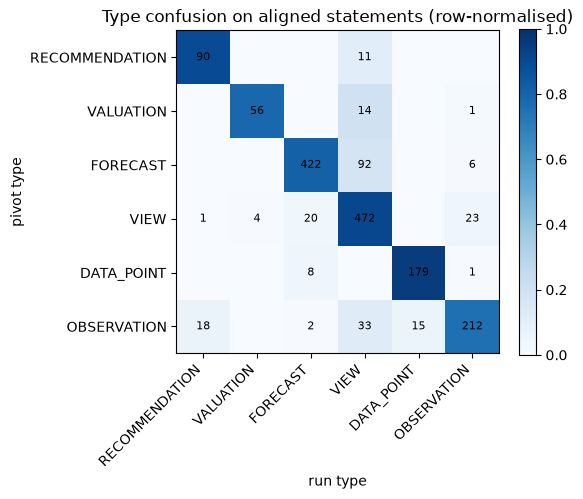

In [6]:
confusion = pd.crosstab(
    aligned["cluster_pivot_claim_type"], aligned["claim_type"], rownames=["pivot type"], colnames=["run type"]
).reindex(index=TYPES, columns=TYPES, fill_value=0)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion.div(confusion.sum(axis=1), axis=0).fillna(0), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(TYPES)), TYPES, rotation=45, ha="right")
ax.set_yticks(range(len(TYPES)), TYPES)
for (i, j), n in pd.DataFrame(confusion.to_numpy()).stack().items():
    if n:
        ax.text(j, i, n, ha="center", va="center", fontsize=8)
ax.set_xlabel("run type")
ax.set_ylabel("pivot type")
ax.set_title("Type confusion on aligned statements (row-normalised)")
fig.colorbar(im, ax=ax)
plt.tight_layout()

In [38]:
# Off-diagonal pairs by rows and by distinct statements (clusters); rows over-weight SundayTea's 20 runs.
off = aligned[aligned["claim_type"] != aligned["cluster_pivot_claim_type"]]
pair = off["cluster_pivot_claim_type"] + " -> " + off["claim_type"]
pairs = pd.DataFrame({
    "rows": pair.value_counts(),
    "clusters": off.groupby(pair)["cluster_id"].nunique(),
    "top_cluster": off.groupby(pair)["cluster_id"].agg(lambda s: s.value_counts().index[0]),
}).sort_values("rows", ascending=False)
pairs["rows_share"] = (pairs["rows"] / pairs["rows"].sum()).round(2)
display(pairs)
# Type sets assigned to the same statement across all runs (including the pivot).
claims.dropna(subset=["cluster_id"]).groupby("cluster_id")["claim_type"].agg(
    lambda s: "|".join(sorted(set(s)))
).loc[lambda s: s.str.contains("|", regex=False)].value_counts().to_frame("clusters")

,rows,clusters,top_cluster,rows_share
FORECAST -> VIEW,92,16,SundayTea:S025,0.37
OBSERVATION -> VIEW,33,13,SundayTea:S005,0.13
VIEW -> OBSERVATION,23,4,SundayTea:S008,0.09
VIEW -> FORECAST,20,6,SundayTea:S052,0.08
OBSERVATION -> RECOMMENDATION,18,2,SundayTea:S068,0.07
OBSERVATION -> DATA_POINT,15,2,SundayTea:S010,0.06
VALUATION -> VIEW,14,1,SundayTea:S040,0.06
RECOMMENDATION -> VIEW,11,2,SundayTea:S030,0.04
DATA_POINT -> FORECAST,8,1,SundayTea:S018,0.03
FORECAST -> OBSERVATION,6,2,Ocado:S009,0.02


,clusters
claim_type,
FORECAST|VIEW,21
OBSERVATION|VIEW,14
DATA_POINT|OBSERVATION,3
RECOMMENDATION|VIEW,3
VALUATION|VIEW,2
OBSERVATION|RECOMMENDATION|VIEW,2
FORECAST|OBSERVATION|VIEW,2
OBSERVATION|VALUATION,1
FORECAST|OBSERVATION,1


In [7]:
# Modality cue length: v0.2 asks for the shortest deciding marker; long cues suggest the field is not standardised.
cue_words = claims["modality_cue"].str.split().str.len()
display(cue_words.groupby([claims["model"], claims["modality"]]).median().unstack())
exclusions.groupby("model")["code"].value_counts().unstack(fill_value=0)

modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
gold,5.0,4.0,3.0
haiku,9.0,7.0,8.0
opus,6.0,6.0,6.5
sonnet,4.0,3.0,3.0


code,META,NON_CLAIM,NOT_LOAD_BEARING,REDUNDANT,TANGENTIAL,TRANSIENT,UNFAITHFUL,VAGUE
model,,,,,,,,
gold,5,4,1,1,14,4,1,0
haiku,25,28,27,8,8,8,0,5
opus,32,4,11,10,12,9,0,2
sonnet,8,14,8,2,15,1,0,4


### Observations

**Reading note.** Rows over-weight SundayTea (20 runs), so a single statement can contribute up to 14 off-diagonal rows (e.g. `SundayTea:S040`). Count clusters (distinct statements), not rows. The SundayTea pivot is `new_rules_v2/opus`, not gold, so its "agreement" means agreement with opus.

#### Type assignment is mostly model-invariant; the disagreement is in the schema

| Measure | Value |
|---|---|
| Rows matching pivot type (all aligned) | 85% (1,431 / 1,680) |
| Gold docs (ING, MS, Ocado) | 91% |
| SundayTea (pivot = opus v2) | 83% |
| Agreement with gold, by model | haiku 0.94, opus 0.90, sonnet 0.88 |
| Statements given >1 type across runs | 50 of 175 clusters (29%); median majority share 0.71 |

- A larger model does not agree more: haiku is closest to gold. The same few statements are contested by all three models, which points to ambiguous **definitions**, not model capability.
- **Stability by type** (share of runs that reproduce the pivot type): DATA_POINT 0.95, VIEW 0.91, RECOMMENDATION 0.89, FORECAST 0.81, VALUATION 0.79, OBSERVATION 0.76. Gold recall: RECOMMENDATION 1.00, DATA_POINT 0.98, VALUATION 0.97, FORECAST 0.94, VIEW 0.89, OBSERVATION 0.66.

#### Confusion structure

| Pair (unordered) | Rows | Share of off-diagonal | Exact type sets (clusters) | Nature |
|---|---|---|---|---|
| FORECAST ↔ VIEW | 112 | 45% | FORECAST\|VIEW 21, + 2 with OBSERVATION | Forward-looking judgement with no measurable outcome |
| OBSERVATION ↔ VIEW | 56 | 22% | OBSERVATION\|VIEW 14, + 4 three-way | Interpretive description of recent events |
| VALUATION ↔ VIEW | 18 | 7% | 2 | Worth judged against fundamentals without cheap/rich wording |
| OBSERVATION ↔ RECOMMENDATION | 18 | 7% | 2 (three-way with VIEW) | **Alignment artefact**: merged statements |
| DATA_POINT ↔ OBSERVATION | 16 | 6% | 3 | What counts as a "substantive number" |
| RECOMMENDATION ↔ VIEW | 12 | 5% | 3 | Negative advice; author-held conviction |
| DATA_POINT ↔ FORECAST | 8 | 3% | 1 | Counterfactual estimate |
| FORECAST ↔ OBSERVATION | 8 | 3% | 1 | Fact vs its forward consequence (Ocado exclusivity) |

- **VIEW is the hub.** Five of the six largest confusions involve VIEW. As the last test in the decision order, VIEW absorbs whatever fails a stricter test.
- **Clean boundaries (0 confusions).** RECOMMENDATION vs VALUATION, FORECAST and DATA_POINT; VALUATION vs FORECAST and DATA_POINT; DATA_POINT vs VIEW. Types with a lexical anchor (an advice verb, a worth-vs-price word, a measured number) are stable.

#### FORECAST ↔ VIEW: 45% of all disagreement

- **The direction flips with the reference.** On SundayTea, pivot FORECAST → run VIEW 91 rows vs 6 the other way. On the gold docs, gold VIEW → model FORECAST 14 vs 1 the other way. Gold is conservative (VIEW), opus v2 is liberal (FORECAST), so there is no stable line.
- **Contested statements** are forward-looking judgements with no tangible outcome:
  - "GBP is well placed to gain in the coming weeks."
  - "The BoE's dovish shift may have to wait until well into 2027."
  - "Idiosyncratic risks surrounding the euro are unlikely to fade anytime soon."
  - "The euro's risk premium could expand further if French bonds continue to lose value."
  - "There is little reason to call for an imminent reversal of the dollar rally."
- **Surface cues do not explain the label.** Within contested clusters, FORECAST vs VIEW rows have similar rates of horizon words (0.35 vs 0.29), risk words (0.28 vs 0.28) and modal verbs (0.16 vs 0.28), and a similar modality mix. The assignment is effectively arbitrary.
- **Root cause in v0.6.** FORECAST includes *"identifiable future outcomes stated as possibilities or risks"* and *"changes in likelihood"*, while VIEW includes *"conditional scenarios and possible catalysts that name no measurable outcome"* and *"current direction or tendency"*. "Well placed to gain" and "unlikely to fade" satisfy both. Candidate fixes:
  - Adopt the v0.2 test, "names a tangible outcome".
  - Alternatively, type forward-looking judgements as VIEW with a `temporal` field and keep FORECAST for outcomes that could be scored.

#### OBSERVATION ↔ VIEW: 22%

- **Factual reports that carry an evaluative word:**
  - "the past week was **defined by** a sharp widening in EGB spreads **rather than** a broad-based sell-off"
  - "**first signs** of broader stress"
  - "UK political uncertainty has **eased**"
  - "US fiscal fundamentals **have not changed**"
  - "Tokyo CPI **signalled** a resurgence"

  The fact-vs-judgement gate has no rule for characterisations.
- **The one clear model effect.** Haiku contributes 23 of 33 OBSERVATION → VIEW rows and 15 of 23 VIEW → OBSERVATION rows.
- **OBSERVATION is the weakest type:** lowest stability (0.76), lowest gold recall (0.66) and the highest unaligned share (35%).

#### Smaller boundaries

- **VALUATION ↔ VIEW:**
  - "OAT-Bund widening has gone further and faster than fundamentals alone would justify" (1 cluster, 14 rows).
  - Ocado: "the existing module portfolio more than covers the debt stack" (gold VIEW, opus and sonnet VALUATION).

  Explicit over/undervaluation wording is never contested.
- **RECOMMENDATION ↔ VIEW:**
  - "Back-end relief is not a reason to turn bullish on the long end": v0.6 puts *advice against* in RECOMMENDATION but *negative assessments that advise no action* in VIEW.
  - "BNPP holds a short MXNCOP position, with greater conviction."
- **DATA_POINT ↔ OBSERVATION:**
  - "3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026" (gold OBSERVATION; opus and sonnet DATA_POINT): do dates and "near peaks" count as a substantive number?
  - "The CNB has long viewed 3.0% as a trigger": is a policy threshold a data point?
- **DATA_POINT ↔ FORECAST:** "Had participation stayed steady, unemployment would have printed 3.9%". Haiku types it FORECAST; counterfactual estimates have no home.
- **Artefacts, not type confusion.** OBSERVATION → RECOMMENDATION (18) and OBSERVATION → DATA_POINT (15) come from runs that merged two claims ("long GBPUSD **to fade** extended short positioning"; "payrolls rose 29k **and** PCE revisions showed…"), which the matcher pairs with the pivot's OBSERVATION. These are atomicity failures.

#### Modality and exclusions

- **Modality agreement is 0.88–1.00.** RECOMMENDATION, DATA_POINT and OBSERVATION are 100% ASSERTED, so modality only carries information for FORECAST (44% non-asserted), VIEW (25%) and VALUATION (21%).
- **`modality_cue` is not standardised.** Median cue length is 7–9 words for haiku vs 3–5 for gold and 3–4 for sonnet; cues are often whole clauses. The v0.2 "shortest deciding marker" rule is needed.
- **Exclusion codes differ by model.** Haiku leans on NON_CLAIM and NOT_LOAD_BEARING; gold uses TANGENTIAL.

## 2. FORECAST

**Working definition (taxonomy v0.7, strict):** *The author's expectation of a measurable outcome, stated with a prospective value and a time horizon.* The extractions in this notebook were produced under v0.6, so expect many current FORECAST rows to fail the v0.7 test.

- Include: price, rate, macro and company forecasts with a level, range or change and a horizon; expected policy decisions at a named meeting or period ("a 25bp hike in December"); measurable outcomes stated as possibilities when a value and horizon are given; nowcasts for a named release; relative or event horizons ("by year-end", "at the next meeting").
- Exclude, as VIEW: anything without a prospective value or without a horizon; direction or tendency without a value ("well placed to gain"); changes in likelihood; risks, catalysts and conditional scenarios; counterfactual estimates.
- Exclude, elsewhere: fair value (VALUATION); third-party forecasts (DATA_POINT).

**Earlier drafts:** `config/claims/forecast.yaml` (subject, assertion, horizon, conditions, attributed_to; `outcome.kind`, `direction`, `comparator`, `scenario_role`). v0.2 ontology: `domain`, `required_truth`, typed `temporal`, `condition` clause/group, `quantities` with `basis`.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `subject` | entity / variable / instrument | Is there always one identifiable subject? |
| `outcome_kind` | level, direction, change, range, event, state | Which kinds occur? Is `event` (policy decision) distinct enough to split? |
| `quantity` | value or min/max, unit, comparator | **Required in v0.7.** How many v0.6 forecasts have one? |
| `horizon` | relation (by, during, within, after, until) + value | **Required in v0.7.** Dates vs events? |
| `horizon` | relation (by, during, within, after, until) + value | How often stated; dates vs events? |
| `condition` | clause or and/or group | Are conditional forecasts typed FORECAST or VIEW in practice? |
| `scenario_role` | baseline, upside_risk, downside_risk, alternative | Do risk-framed forecasts need it? |
| `required_truth` | true / false | How common are negated forecasts ("we do not expect")? |
| `basis` | analyst_forecast, nowcast, model_assumption | Is the nowcast inclusion applied consistently? |
| `attributed_to` | null / third party | Leakage of third-party forecasts that should be DATA_POINT |
| `domain` | market_price, macroeconomics, policy, corporate_fundamentals, market_expectations, positioning, valuation | Does domain cut FORECAST cleanly? |
**Boundaries:** FORECAST↔VIEW is now decided by value + horizon; FORECAST↔DATA_POINT (consensus, third party, nowcast); FORECAST↔VALUATION (future misvaluation).
**Boundaries:** FORECAST↔VIEW (momentum, risk, conditional scenario), FORECAST↔DATA_POINT (consensus, third party, nowcast), FORECAST↔VALUATION (future misvaluation).

In [8]:
forecasts = of_type("FORECAST")
display(pd.crosstab(forecasts["doc"], forecasts["model"]))
display(by_model(forecasts, "modality"))
forecasts.sample(min(15, len(forecasts)), random_state=0)[SHOW]

model,gold,haiku,opus,sonnet
doc,,,,
ING,8,27,40,22
MS,1,3,3,2
Ocado,9,15,14,6
SundayTea,0,167,142,127


modality,ASSERTED,HEDGED,SPECULATIVE
model,,,
haiku,0.55,0.35,0.10
sonnet,0.57,0.36,0.06
opus,0.57,0.33,0.10
gold,0.61,0.22,0.17


,run_id,statement_id,claim_type,modality,modality_cue,statement
1014,new_rules/Ocado/opus,S022,FORECAST,ASSERTED,our model assuming,J.P. Morgan's model assumes no uncommitted CFC expansion.
360,ablation/B2_rules/opus,S023,FORECAST,HEDGED,we see scope for wider term premiums,US term premiums have scope to widen.
2134,sunday_tea_model_comparison_v2/haiku,S034,FORECAST,HEDGED,suggests a near -zero chance,The ECB has a near-zero chance of hiking again in October.
712,ablation/B4_no_example/sonnet,S027,FORECAST,ASSERTED,we also now see,CNB will hike 25bp in November then hold into late 2027.
1648,new_rules_v2/SundayTea/haiku,S016,FORECAST,SPECULATIVE,could necessitate an even tighter monetary policy stance,Lower energy prices could necessitate an even tighter US monetary policy stance.
399,ablation/B2_rules/opus,S062,FORECAST,ASSERTED,set to temporarily exceed the CNB’s tolerance band,Czech inflation will temporarily exceed the CNB's tolerance band by early 2027.
2088,sunday_tea_model_comparison/sonnet,S010,FORECAST,HEDGED,likely to prefer,"The ECB will deliver fewer hikes than the market has priced, preferring high for longer."
62,ablation/B0_baseline/opus,S063,FORECAST,ASSERTED,set to temporarily exceed,Czech inflation will temporarily exceed the CNB's tolerance band by early 2027.
193,ablation/B1_thinking/sonnet,S004,FORECAST,ASSERTED,continue to expect,"BNP Paribas expects at least two more FOMC hikes, to remove last year’s insurance cuts and take policy to a more neutral real level."
2065,sunday_tea_model_comparison/opus,S070,FORECAST,ASSERTED,we believe,The probability of a further 25bp BanRep hike at the 30 October decision has risen.


In [35]:
MONTHS = r"January|February|March|April|June|July|August|September|October|November|December"
FORECAST_PROBES = {
    "number": r"\d",
    "percent_bp": r"%|(?:\d\s?|\b)bps?\b|basis points?|(?:\d\s?|\b)pp\b",
    "level_target": r"\b(?:to|at|towards?|reach(?:es|ing)?|around|near)\s+[-+]?[$€£]?\d",
    "direction_up": r"\b(?:rise|rises|rising|increase\w*|higher|strengthen\w*|appreciat\w*|gain\w*|rall\w*|hike\w*|accelerat\w*)\b",
    "direction_down": r"\b(?:fall|falls|falling|decline\w*|lower|weaken\w*|depreciat\w*|drop\w*|cut\w*|eas(?:e|es|ing)|slow\w*)\b",
    "stable": r"\b(?:stable|unchanged|steady|range[- ]?bound|flat|on hold)\b",
    "horizon_date": rf"\b(?:20\d\d|Q[1-4]|[12]H\d\d|FY\d{{2,4}}|year[- ]end|end[- ]\d{{4}}|(?:this|next|coming) (?:week|month|quarter|year)s?|{MONTHS})\b",
    "horizon_event": r"\b(?:meeting|FOMC|ECB|BoE|Fed|budget|election|release|payrolls|CPI|earnings|results)\b",
    "condition": r"\b(?:if|unless|provided|assuming|in the event|once)\b",
    "negation": r"\b(?:not|no|never|unlikely|without)\b|n't",
    "scenario_risk": r"\b(?:base[- ]case|baseline|upside|downside|scenario|risks?|tail)\b",
    "third_party": r"\b(?:consensus|according to|markets? (?:expect|pric)\w*|investors expect)\b",
}
fill_rates(forecasts, FORECAST_PROBES)

model,gold,haiku,opus,sonnet
number,0.50,0.30,0.28,0.37
percent_bp,0.17,0.20,0.14,0.20
level_target,0.22,0.03,0.03,0.04
direction_up,0.17,0.36,0.36,0.53
direction_down,0.17,0.10,0.14,0.13
stable,0.00,0.08,0.03,0.06
horizon_date,0.39,0.44,0.47,0.57
horizon_event,0.06,0.20,0.28,0.38
condition,0.00,0.01,0.03,0.01
negation,0.06,0.05,0.08,0.05


In [10]:
pd.concat([forecasts[["model", "statement"]], first_match(forecasts, FORECAST_PROBES)], axis=1).head(20)

,model,statement,number,percent_bp,level_target,direction_up,direction_down,stable,horizon_date,horizon_event,condition,negation,scenario_risk,third_party
6,opus,The FOMC will skip in October and wait until December before removing further accommodation.,NaN,NaN,NaN,NaN,NaN,NaN,October,FOMC,NaN,NaN,NaN,NaN
13,opus,"The FOMC will deliver at least two more hikes, removing last year's 'insurance' cuts and taking policy to a more neutral level in real terms.",NaN,NaN,NaN,hikes,cuts,NaN,NaN,FOMC,NaN,NaN,NaN,NaN
15,opus,There is some scope for downside pressure on crude and product prices in the near term.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,downside,NaN
22,opus,US term premiums have scope to widen.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24,opus,There is a near-zero chance that the ECB Governing Council hikes again in October.,NaN,NaN,NaN,hikes,NaN,NaN,October,ECB,NaN,NaN,NaN,NaN
26,opus,The ECB will hike once more in December and then pause for an extended period.,NaN,NaN,NaN,hike,NaN,NaN,December,ECB,once,NaN,NaN,NaN
27,opus,"The ECB will deliver fewer rate increases than the market has priced, likely preferring a 'high for longer' strategy.",NaN,NaN,NaN,increases,NaN,NaN,NaN,ECB,NaN,NaN,NaN,NaN
38,opus,There is downside risk to BNP Paribas's 1.14 year-end EURUSD target.,1,NaN,NaN,NaN,NaN,NaN,year-end,NaN,NaN,NaN,downside,NaN
43,opus,Further tax rises or spending cuts will likely be needed to fully fund the social care service.,NaN,NaN,NaN,rises,cuts,NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,opus,The past week's events have raised the probability that the BoJ pursues a quarterly hiking cycle in the near term.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
display(boundary_summary("FORECAST"))
boundary("FORECAST")[["cluster_id", "model", *SHOW]].head(40)

claim_type
VIEW           123
OBSERVATION     14
DATA_POINT       4
Name: count, dtype: int64

,cluster_id,model,run_id,statement_id,claim_type,modality,modality_cue,statement
2300,ING:S007,gold,gold/ING,S007,VIEW,ASSERTED,we see little reason to call for an imminent reversal,There is little reason to call for an imminent reversal of the dollar rally.
1300,ING:S007,haiku,new_rules_v2/ING/haiku,S007,VIEW,ASSERTED,we see little reason to call,There is little reason to call for an imminent reversal in dollar momentum.
782,ING:S007,opus,new_rules/ING/opus,S002,FORECAST,ASSERTED,we see little reason to call for an imminent reversal,ING sees little reason to call for an imminent reversal in dollar momentum.
1355,ING:S007,opus,new_rules_v2/ING/opus,S002,FORECAST,ASSERTED,we see little reason to call for an imminent reversal,ING sees little reason to call for an imminent reversal in dollar momentum.
844,ING:S007,sonnet,new_rules/ING/sonnet,S001,VIEW,ASSERTED,we see little reason to call for an imminent reversal,There is little reason to call for an imminent reversal of the dollar rally given no clear macro or market catalyst.
1413,ING:S007,sonnet,new_rules_v2/ING/sonnet,S001,FORECAST,ASSERTED,we see little reason to call for,There is little reason to call for an imminent reversal of the dollar rally.
2311,ING:S018,gold,gold/ING,S018,VIEW,HEDGED,could expand further,"The euro’s risk premium could expand further if French bonds continue to lose value, though this is not the baseline."
750,ING:S018,haiku,new_rules/ING/haiku,S029,VIEW,SPECULATIVE,could expand further if French bonds continue to lose value,The risk premium could expand further if French bonds continue to lose value.
1317,ING:S018,haiku,new_rules_v2/ING/haiku,S024,VIEW,SPECULATIVE,could expand further if French bonds continue to lose value,The risk premium could expand further if French bonds continue to lose value.
805,ING:S018,opus,new_rules/ING/opus,S025,FORECAST,SPECULATIVE,could expand further,The euro risk premium could expand further if French bonds continue to lose value.


In [12]:
# Most common non-asserted cues.
hedged = forecasts[forecasts["modality"] != "ASSERTED"]
hedged.groupby("modality")["modality_cue"].apply(lambda s: s.str.lower().value_counts().head(10)).to_frame("n")

n
modality                                                                                
HEDGED      suggests that the likelihood of a consecutive hike in october is limited  14
            is likely to remain on hold                                                8
            suggests a near -zero chance                                               8
            seems to be the neutral scenario                                           7
            likely to prefer                                                           7
            more likely now we expect                                                  7
            we see scope for wider term premiums                                       5
            will likely be necessary                                                   5
            likely to prefer a ‘high for longer’ strategy                              5
            suggesting a tie in the second round                                       5
SPECULATIVE could shift tightening out to early next year                             16
            we see scope for wider term premiums                                       8
            could shift                                                                5
            room for risk premium to continue to rise                                  5
            remains the risk                                                           4
            potentially further debt reduction                                         3
            could expand further                                                       2
            could necessitate an even tighter monetary policy stance                   2
            representing downside risk                                                 1
            could shift tightening out                                                 1

### Observations

| Field | Fill rate (models) | Gold | Implication |
|---|---|---|---|
| any number | 0.28–0.37 | 0.50 | About two-thirds of model forecasts are unquantified |
| explicit level / target | 0.03–0.04 | 0.22 | `quantity` is mostly empty |
| % / bp / pp | 0.14–0.20 | 0.17 | |
| direction up / down | 0.36–0.53 / 0.10–0.14 | 0.17 / 0.17 | Direction is the main payload; models skew to "up" |
| date-like horizon | 0.44–0.57 | 0.39 | A `temporal` field is worth having |
| event-anchored horizon | 0.20–0.38 | 0.06 | Event anchors (FOMC, budget, election) are common |
| condition (if/unless/once) | 0.01–0.03 | 0.00 | Rare; a nested `condition` is low priority |
| negation | 0.05–0.08 | 0.06 | `required_truth: false` is uncommon but real |
| scenario / risk words | 0.13–0.23 | 0.00 | Risk-framed forecasts exist only in model output |
| third-party | 0.00 | 0.00 | Third-party forecasts are routed to DATA_POINT as intended |

- **Models over-produce soft forecasts.** Gold has 8 forecasts in ING vs 11–20 per model run, and gold forecasts are more quantified. The extra model forecasts are the forward-looking judgements contested with VIEW (§1).
- **Highest hedging of any type.** Modality is 56% ASSERTED, 34% HEDGED and 9% SPECULATIVE.
- **Cues are clauses, not markers.** For example "suggests that the likelihood of a consecutive hike in October is limited" and "could shift tightening out to early next year". The shortest-marker rule would reduce these to "suggests" and "could".
- **Boundaries:**
  - VIEW dominates (§1).
  - DATA_POINT: a counterfactual estimate ("would have printed 3.9%").
  - OBSERVATION: Ocado "Exclusivity has rolled off in key markets" matches a gold FORECAST. Check whether the gold statement merges the fact with its forward consequence.
- **Schema direction.** Keep `direction` and `temporal` (relation + value, with event anchors) as core fields, `quantity` optional, and `scenario_role` only if the FORECAST/VIEW line is redrawn to admit risk-framed outcomes.

## 3. DATA_POINT

**Working definition (taxonomy v0.7):** *A reported or attributed fact that carries a substantive number, or a rating or estimate attributed to a third party.* Fixed modality `ASSERTED`; allowed only in the `rationale` role.

- Include: published data, prices, yields, positioning and flow figures; quantified consensus or market pricing; quantified policy terms and thresholds; third-party ratings, forecasts and estimates.
- Exclude: the author's own estimates (FORECAST); counterfactual estimates (VIEW); house model outputs about value (VALUATION).

**Earlier draft:** `config/claims/data_point.yaml`: `observation_kind` (measurement, change, event, reported_state), `measurement` {variable, value, unit, period, comparator}, `previous_value`.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `observation_kind` | measurement, change, event, reported_state | Does each row fit one kind? |
| `metric` / `variable` | free text, later a registry id | Can a metric name be recovered for every row? |
| `value` | point or range | One number per row (atomicity)? |
| `unit` | %, bp, x, currency amount, index points | Which units occur? |
| `period` / `as_of` | date, month, quarter, y/y | How often is the reference period stated? |
| `comparator` | equal, greater_than, less_than, at_least, at_most | Frequency of thresholds and records |
| `previous_value` / `change` | number, from→to | Should change be its own kind? |
| `source` / `attributed_to` | agency, consensus, broker, rating agency | Are third-party *opinions* mixed with *facts*? |
| `basis` | reported, market_implied, consensus, third_party_forecast | Market pricing here vs a `market_expectations` view |
| `entity` | country, company, instrument | |

**Boundaries:** DATA_POINT↔OBSERVATION (substantive-number threshold), ↔FORECAST (nowcast, third party), ↔POSITIONING (CFTC and flow figures), ↔VALUATION (model outputs).

In [13]:
data_points = of_type("DATA_POINT")
display(pd.crosstab(data_points["doc"], data_points["model"]))
# Fixed modality: anything other than ASSERTED is a rule violation.
display(by_model(data_points, "modality"))
data_points.sample(min(15, len(data_points)), random_state=0)[SHOW]

model,gold,haiku,opus,sonnet
doc,,,,
ING,4,11,14,9
MS,4,15,16,14
Ocado,2,10,6,2
SundayTea,0,63,48,44


modality,ASSERTED
model,
haiku,1.0
sonnet,1.0
opus,1.0
gold,1.0


,run_id,statement_id,claim_type,modality,modality_cue,statement
1639,new_rules_v2/SundayTea/haiku,S007,DATA_POINT,ASSERTED,the whopping 406k rise in employment as measured by the household survey,Household-survey employment rose 406k.
1399,new_rules_v2/ING/opus,S046,DATA_POINT,ASSERTED,rose from 6.2% to 6.6%,"Romanian inflation rose from 6.2% to 6.6% in September, exceeding market expectations."
1307,new_rules_v2/ING/haiku,S014,DATA_POINT,ASSERTED,Consensus is already looking for a modest 0.2% core CPI MoM print,Consensus is looking for a modest 0.2% core CPI MoM print tomorrow.
72,ablation/B0_baseline/sonnet,S002,DATA_POINT,ASSERTED,29k rise in nonfarm payrolls,September nonfarm payrolls rose a relatively soft 29k and PCE revisions showed a slightly softer underlying core inflation pace.
950,new_rules/MS/sonnet,S017,DATA_POINT,ASSERTED,rose by roughly 33%,"In the first five years of Help to Buy (2013–2018), combined completions across Persimmon, Taylor Wimpey and Barratt rose by roughly 33%."
1975,sunday_tea_model_comparison/haiku,S073,DATA_POINT,ASSERTED,Colombia’s Banrep surprised again with a 25bp hike in its policy rate,"Banrep hiked its policy rate by 25bp, above market and house expectations for a pause at 12.0%."
1753,new_rules_v2/SundayTea/opus,S009,DATA_POINT,ASSERTED,The relatively soft 29k rise in nonfarm payrolls,US nonfarm payrolls rose by a relatively soft 29k in September.
1564,new_rules_v2/Ocado/haiku,S031,DATA_POINT,ASSERTED,including £765m of cash and a £300m undrawn RCF,Ocado has £765m of cash and a £300m undrawn RCF.
1487,new_rules_v2/MS/opus,S004,DATA_POINT,ASSERTED,"30Y at 5.51%, highest since 2004","The 30Y Treasury yield reached 5.51%, its highest since 2004, pushing the long end of the curve to generational extremes."
1512,new_rules_v2/MS/sonnet,S002,DATA_POINT,ASSERTED,"30Y at 5.51%, highest since 2004","The 30Y Treasury yield reached 5.51%, the highest since 2004, leaving US 30y fixed mortgages at 7.18%."


In [36]:
DATA_POINT_PROBES = {
    "percent": r"%|per ?cent",
    "bp": r"(?:\d\s?|\b)bps?\b|basis points?",
    "currency_amount": r"[$€£¥]\s?\d|\b(?:bn|mn|billion|million|trillion)\b",
    "multiple": r"\d(?:\.\d+)?x\b",
    "period": rf"\b(?:20\d\d|Q[1-4]|[12]H\d\d|FY\d{{2,4}}|y/y|yoy|m/m|mom|q/q|week|month|quarter|{MONTHS})\b",
    "change_from_to": r"\bfrom\b[^.]*\bto\b|\b(?:rose|fell|increased|decreased|climbed|dropped|slipped|jumped)\b",
    "comparator": r"\b(?:above|below|more than|less than|at least|at most|over|under|exceed\w*|record)\b",
    "attribution": r"\b(?:according to|consensus|survey|reported|data show\w*|published|estimates?|forecasts?|expects?)\b",
    "market_implied": r"\b(?:priced|pricing|implied|OIS|futures|swaps?|forwards?)\b",
    "rating_agency": r"\b(?:Moody'?s|S&P|Fitch|rated|rating)\b",
    "positioning_data": r"\b(?:CFTC|IMM|positioning|flows?|open interest|holdings|longs?|shorts?)\b",
}
fill_rates(data_points, DATA_POINT_PROBES)

model,gold,haiku,opus,sonnet
percent,0.9,0.46,0.55,0.58
bp,0.0,0.16,0.15,0.25
currency_amount,0.1,0.11,0.10,0.06
multiple,0.0,0.00,0.00,0.00
period,0.5,0.30,0.42,0.45
change_from_to,0.2,0.27,0.26,0.32
comparator,0.1,0.17,0.11,0.20
attribution,0.1,0.11,0.15,0.16
market_implied,0.0,0.00,0.00,0.00
rating_agency,0.0,0.00,0.00,0.00


In [15]:
# Atomicity: how many numbers does one DATA_POINT carry?
n_numbers = data_points["statement"].str.count(r"\d+(?:[.,]\d+)?").clip(upper=4).rename("numbers (4 = 4+)")
display(pd.crosstab(data_points["model"], n_numbers))
data_points[n_numbers >= 3][SHOW].head(15)

numbers (4 = 4+),0,1,2,3,4
model,,,,,
gold,0,3,5,1,1
haiku,3,45,37,14,0
opus,0,35,32,15,2
sonnet,0,23,23,18,5


,run_id,statement_id,claim_type,modality,modality_cue,statement
11,ablation/B0_baseline/opus,S012,DATA_POINT,ASSERTED,the whopping 406k rise in employment,"Household-survey employment rose 406k, hours worked increased, and the rise in unemployment from 4.1% to 4.2% was driven mainly by higher participation."
30,ablation/B0_baseline/opus,S031,DATA_POINT,ASSERTED,briefly touched 150bp on Friday,"The 10y OAT-Bund spread briefly touched 150bp on Friday, its highest since 2012."
74,ablation/B0_baseline/sonnet,S004,DATA_POINT,ASSERTED,406k rise in employment,"The household survey employment rose 406k and unemployment rose from 4.1% to 4.2% mainly because of higher participation, indicating a stronger underlying l..."
83,ablation/B0_baseline/sonnet,S013,DATA_POINT,ASSERTED,150bp,"The 10y OAT-Bund spread briefly touched 150bp, its highest since 2012."
136,ablation/B1_thinking/haiku,S032,DATA_POINT,ASSERTED,"briefly touched 150bp on Friday, its highest since 2012","The 10y OAT-Bund spread briefly touched 150bp, its highest since 2012."
196,ablation/B1_thinking/sonnet,S007,DATA_POINT,ASSERTED,406k rise in employment,"The household survey showed a 406k rise in employment, and the unemployment rate rose from 4.1% to 4.2% mainly because of higher participation."
212,ablation/B1_thinking/sonnet,S023,DATA_POINT,ASSERTED,briefly touched 150bp,"The 10y OAT-Bund spread briefly touched 150bp on Friday, its highest since 2012."
286,ablation/B2_rules/haiku,S045,DATA_POINT,ASSERTED,briefly touched 150bp on Friday,"The 10y OAT-Bund spread briefly touched 150bp on Friday, its highest since 2012."
350,ablation/B2_rules/opus,S013,DATA_POINT,ASSERTED,the whopping 406k rise in employment,"Household-survey employment rose 406k and hours worked increased; the unemployment rate rose from 4.1% to 4.2% mainly because participation rose, and with s..."
367,ablation/B2_rules/opus,S030,DATA_POINT,ASSERTED,briefly touched 150bp on Friday,"The 10y OAT-Bund spread briefly touched 150bp on Friday, its highest since 2012, at the height of the eurozone sovereign debt crisis."


In [16]:
display(boundary_summary("DATA_POINT"))
boundary("DATA_POINT")[["cluster_id", "model", *SHOW]].head(40)

claim_type
OBSERVATION    13
FORECAST        8
Name: count, dtype: int64

,cluster_id,model,run_id,statement_id,claim_type,modality,modality_cue,statement
2299,ING:S006,gold,gold/ING,S006,OBSERVATION,ASSERTED,near the peaks seen in March 2025 and March 2026,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
728,ING:S006,haiku,new_rules/ING/haiku,S007,OBSERVATION,ASSERTED,Options markets are sending the same signal,Options markets show 3m DXY-weighted risk reversals near the peaks seen in March 2025 and March 2026.
1299,ING:S006,haiku,new_rules_v2/ING/haiku,S006,OBSERVATION,ASSERTED,near the peaks seen in March 2025 and March 2026,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
792,ING:S006,opus,new_rules/ING/opus,S012,DATA_POINT,ASSERTED,near the peaks seen in March 2025 and March 2026,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
1362,ING:S006,opus,new_rules_v2/ING/opus,S009,DATA_POINT,ASSERTED,near the peaks,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
847,ING:S006,sonnet,new_rules/ING/sonnet,S004,DATA_POINT,ASSERTED,near the peaks,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
1418,ING:S006,sonnet,new_rules_v2/ING/sonnet,S006,DATA_POINT,ASSERTED,near the peaks,3m DXY-weighted risk reversals are near the peaks seen in March 2025 and March 2026.
2326,ING:S033,gold,gold/ING,S033,DATA_POINT,ASSERTED,has long viewed 3.0% as a potential trigger,The CNB has long viewed 3.0% as a potential trigger for rate hikes.
774,ING:S033,haiku,new_rules/ING/haiku,S053,DATA_POINT,ASSERTED,has long viewed 3.0% as a potential trigger for rate hikes,The CNB has long viewed 3.0% as a potential trigger for rate hikes.
1345,ING:S033,haiku,new_rules_v2/ING/haiku,S052,DATA_POINT,ASSERTED,has long viewed 3.0% as a potential trigger for rate hikes,The CNB has long viewed 3.0% as a potential trigger for rate hikes.


### Observations

- **The cleanest type.** Stability 0.95, gold recall 0.98, never confused with VIEW, and 100% ASSERTED across every model (the fixed-modality rule is respected).
- **Small unit vocabulary:**

| Unit / field | Fill rate (models) | Gold |
|---|---|---|
| % | 0.46–0.58 | 0.90 |
| bp | 0.15–0.25 | 0.00 |
| currency amount | 0.06–0.11 | 0.10 |
| multiple (x) | 0.00 | 0.00 |
| period stated | 0.30–0.45 | 0.50 |
| change / from→to | 0.26–0.32 | 0.20 |
| comparator / record | 0.11–0.20 | 0.10 |
| attribution | 0.11–0.16 | 0.10 |
| market-implied, rating agency | 0.00 | 0.00 |

- **`observation_kind: change` with `previous_value` is common enough to keep.** About 30% of rows report a move ("rose from 4.1% to 4.2%").
- **Atomicity fails.** Over half of model DATA_POINTs carry two or more numbers (haiku 52%, opus 58%, sonnet 67%), and 14–33% carry three or more. A typical example: "employment rose 406k … unemployment rose from 4.1% to 4.2% … driven by participation".
  - Either enforce one measurement per claim, or allow `measurements[]`.
  - Sonnet packs the most numbers per statement.
- **Market pricing does not land here.** The market-implied probe fires for 38% of **VALUATION** rows and 0% of DATA_POINT rows. Statements about what is priced are typed as valuation judgements ("rate pricing is hawkish"), which is closer to the v0.2 `market_expectations` domain than to a data point.
- **Positioning figures live here today.** Examples: "Net long USD positioning vs G10 reached 24% of open interest"; "HF net positioning in Memory is ~6% of global net exposure vs ~12% at peaks" (positioning words: models 8–17%, gold 40%). These would move to POSITIONING (§6).
- **Boundaries:**
  - OBSERVATION (13 rows): dates and peaks without a measured value; policy thresholds ("CNB viewed 3.0% as a trigger").
  - FORECAST (8 rows): the counterfactual.
  - **Proposed rule:** a substantive number is a measured value of a variable; dates, peaks and thresholds alone do not qualify.

## 4. VALUATION

**Working definition (taxonomy v0.7):** *An assessment of worth relative to market price, fundamentals or another reference point, whether or not the words over- or undervalued are used.*

- Include: fair value, cheap or rich, over- or undervalued, relative value; **moves that have gone further than fundamentals justify** ("OAT-Bund widening has gone further and faster than fundamentals alone would justify"); **asset or collateral coverage** ("the existing module portfolio more than covers the debt stack"); qualitative assessments against fundamentals; implied enterprise or asset value; valuation ratios such as loan-to-value; house valuation-model outputs.
- Exclude: expected future price levels or targets (FORECAST); raw market data such as yields and spreads (DATA_POINT).

**Earlier drafts:** `config/claims/valuation.yaml`: `assessment` (cheap, rich, fair, mispriced, indeterminate, overvalued, undervalued), `reference.kind` (fundamentals, model, historical, relative, required_compensation), `deviation` {value, unit, direction}, `fair_value`. v0.2 folds VALUATION into view/forecast with `domain: valuation` plus `ValuationDetail` {method, reference_level}.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `assessment` | undervalued (cheap), overvalued (rich), fair_value, mispriced, attractive | Is the vocabulary small and stable? |
| `reference_kind` | model, historical, relative, fundamentals, required_compensation, unspecified | Is the reference usually stated? |
| `method` | e.g. short-term valuation model, DCF, BEER, multiples | |
| `deviation` | value + unit (%, bp, σ) + direction (above, below, aligned) | Share quantified |
| `reference_level` | stated fair-value level | Ever stated explicitly? |
| `benchmark` | peer, basket, index, history | Relative-value claims vs absolute |
| `threshold` | σ, z-score, percentile | |
| `horizon` | as-of vs future | Is a future valuation a FORECAST? |
| `subject_scope` | one entity vs group | Group values ("EUR, SEK and NZD") |

**Key question:** keep VALUATION as a type, or fold it into VIEW/FORECAST with `domain: valuation` (v0.2)? Check the VALUATION↔VIEW disagreement rate below.

In [17]:
valuations = of_type("VALUATION")
display(pd.crosstab(valuations["doc"], valuations["model"]))
display(by_model(valuations, "modality"))
valuations[SHOW]

model,gold,haiku,opus,sonnet
doc,,,,
ING,5,10,10,7
Ocado,2,9,6,4
SundayTea,0,8,8,8


modality,ASSERTED,HEDGED
model,,
haiku,0.74,0.26
sonnet,0.84,0.16
opus,0.75,0.25
gold,1.00,0.00


,run_id,statement_id,claim_type,modality,modality_cue,statement
31,ablation/B0_baseline/opus,S032,VALUATION,HEDGED,Our fundamental analysis suggests,"A 150bp 10y OAT-Bund spread, briefly reached on Friday, is consistent with the market pricing France as heading towards BBB+."
85,ablation/B0_baseline/sonnet,S015,VALUATION,ASSERTED,would be a level consistent with,150bp on 10y OAT-Bund is consistent with the market pricing a country heading toward BBB+.
139,ablation/B1_thinking/haiku,S035,VALUATION,HEDGED,suggests that 150bp on 10y OAT-Bund spreads would be a level consistent,150bp on 10y OAT-Bund spreads would be consistent with the market pricing a country going towards BBB+.
211,ablation/B1_thinking/sonnet,S022,VALUATION,HEDGED,suggests,A 150bp 10y OAT-Bund spread is consistent with the market pricing a country going towards BBB+.
288,ablation/B2_rules/haiku,S047,VALUATION,HEDGED,suggests that 150bp on 10y OAT-Bund spreads would be a level consistent,150bp on 10y OAT-Bund spreads would be a level consistent with the market pricing a country going towards BBB+.
369,ablation/B2_rules/opus,S032,VALUATION,HEDGED,Our fundamental analysis suggests,"A 10y OAT-Bund spread of 150bp is consistent with the market pricing France as heading towards a BBB+ rating, a level reached briefly on Friday."
426,ablation/B2_rules/sonnet,S020,VALUATION,HEDGED,suggests,Fundamental analysis indicates 150bp on 10y OAT-Bund is consistent with the market pricing France towards BBB+.
497,ablation/B3_ing_example/haiku,S041,VALUATION,ASSERTED,would be a level consistent with the market pricing a country going towards BBB+,10y OAT-Bund at 150bp would be consistent with market pricing a country going towards BBB+.
572,ablation/B3_ing_example/sonnet,S020,VALUATION,ASSERTED,Our fundamental analysis suggests,BNPP fundamental analysis suggests 150bp on 10y OAT-Bund is consistent with the market pricing a country going towards BBB+.
636,ablation/B4_no_example/haiku,S038,VALUATION,HEDGED,suggests,150bp on 10y OAT-Bund would be consistent with the market pricing a country going towards BBB+.


In [18]:
VALUATION_PROBES = {
    "cheap_under": r"\b(?:cheap\w*|undervalu\w*|discount\w*|attractive\w*|below fair)\b",
    "rich_over": r"\b(?:rich|richer|richly|overvalu\w*|expensive|premium|stretched|above fair)\b",
    "fair": r"\bfair(?:ly)?[- ]valu\w*|\bfair value\b|\bfairly priced\b",
    "mispriced": r"\bmispric\w*|\bdislocat\w*",
    "ref_model": r"\bmodel\w*|\bBEER\b|\bPPP\b|\bDCF\b|\bregression\b",
    "ref_historical": r"\bhistor\w*|\baverage\b|\bpercentile\b|\bsince\b|\blong[- ]run\b",
    "ref_relative": r"\b(?:relative to|versus|vs\.?|against|compared|peers?|basket)\b",
    "ref_fundamentals": r"\bfundamental\w*|\bearnings\b|\bP/?E\b|\bEV/|\bEBITDA\b|\bmultiples?\b|\bbook value\b|\bLTV\b|loan[- ]to[- ]value",
    "ref_compensation": r"\bspreads?\b|\bcarry\b|\byields?\b|\bcompensat\w*|\brisk premi\w*",
    "deviation_size": r"\d+(?:\.\d+)?\s?(?:%|bps?\b|sd\b|σ|standard deviations?|x\b)",
    "threshold_sigma": r"standard deviation|σ|sigma|z-?score",
    "future_reference": r"\bwill\b|\bby (?:end|year)|\bexpect\w*",
}
fill_rates(valuations, VALUATION_PROBES)

model,gold,haiku,opus,sonnet
cheap_under,0.29,0.15,0.17,0.16
rich_over,0.14,0.15,0.17,0.11
fair,0.43,0.19,0.25,0.21
mispriced,0.00,0.00,0.00,0.00
ref_model,0.29,0.07,0.08,0.11
ref_historical,0.00,0.00,0.00,0.00
ref_relative,0.57,0.30,0.29,0.32
ref_fundamentals,0.29,0.19,0.29,0.42
ref_compensation,0.00,0.22,0.25,0.16
deviation_size,0.57,0.59,0.58,0.79


In [19]:
pd.concat([valuations[["model", "statement"]], first_match(valuations, VALUATION_PROBES)], axis=1)

,model,statement,cheap_under,rich_over,fair,mispriced,ref_model,ref_historical,ref_relative,ref_fundamentals,ref_compensation,deviation_size,threshold_sigma,future_reference
31,opus,"A 150bp 10y OAT-Bund spread, briefly reached on Friday, is consistent with the market pricing France as heading towards BBB+.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,spread,150bp,NaN,NaN
85,sonnet,150bp on 10y OAT-Bund is consistent with the market pricing a country heading toward BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150bp,NaN,NaN
139,haiku,150bp on 10y OAT-Bund spreads would be consistent with the market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,spreads,150bp,NaN,NaN
211,sonnet,A 150bp 10y OAT-Bund spread is consistent with the market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,spread,150bp,NaN,NaN
288,haiku,150bp on 10y OAT-Bund spreads would be a level consistent with the market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,spreads,150bp,NaN,NaN
369,opus,"A 10y OAT-Bund spread of 150bp is consistent with the market pricing France as heading towards a BBB+ rating, a level reached briefly on Friday.",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,spread,150bp,NaN,NaN
426,sonnet,Fundamental analysis indicates 150bp on 10y OAT-Bund is consistent with the market pricing France towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fundamental,NaN,150bp,NaN,NaN
497,haiku,10y OAT-Bund at 150bp would be consistent with market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150bp,NaN,NaN
572,sonnet,BNPP fundamental analysis suggests 150bp on 10y OAT-Bund is consistent with the market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fundamental,NaN,150bp,NaN,NaN
636,haiku,150bp on 10y OAT-Bund would be consistent with the market pricing a country going towards BBB+.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,150bp,NaN,NaN


In [20]:
display(boundary_summary("VALUATION"))
boundary("VALUATION")[["cluster_id", "model", *SHOW]]

claim_type
VIEW           15
OBSERVATION     1
Name: count, dtype: int64

,cluster_id,model,run_id,statement_id,claim_type,modality,modality_cue,statement
2333,ING:S040,gold,gold/ING,S040,VALUATION,ASSERTED,we still see 24.250 as fair value,The koruna’s fair value is 24.250 given current hawkish rate pricing.
1352,ING:S040,haiku,new_rules_v2/ING/haiku,S059,OBSERVATION,ASSERTED,given current hawkish rate pricing,Current rate pricing is hawkish.
842,ING:S040,opus,new_rules/ING/opus,S062,VALUATION,ASSERTED,we still see 24.250 as fair value,ING still sees 24.250 as fair value for the Czech koruna given current rate pricing.
1412,ING:S040,opus,new_rules_v2/ING/opus,S059,VALUATION,ASSERTED,we still see 24.250 as fair value,ING sees 24.250 as fair value for the Czech koruna given current hawkish rate pricing.
873,ING:S040,sonnet,new_rules/ING/sonnet,S030,VALUATION,ASSERTED,we still see 24.250 as fair value,The Czech koruna is seen at fair value of 24.250 given hawkish rate pricing.
1447,ING:S040,sonnet,new_rules_v2/ING/sonnet,S035,VALUATION,ASSERTED,we still see 24.250 as fair value,The Czech koruna’s fair value is 24.250 given current hawkish rate pricing.
2351,Ocado:S004,gold,gold/Ocado,S004,VIEW,ASSERTED,more than covers,"The present value of Ocado’s existing modules more than covers its debt stack, leaving valuation unchallenged even before assigning value to future contract..."
996,Ocado:S004,opus,new_rules/Ocado/opus,S004,VALUATION,ASSERTED,supporting our view that,"Ocado's valuation is unchallenged: its existing module portfolio more than covers the debt stack even before any value is assigned to future contract wins, ..."
1583,Ocado:S004,opus,new_rules_v2/Ocado/opus,S005,VALUATION,ASSERTED,supporting our view that,"Ocado's valuation is unchallenged: the existing module portfolio more than covers the debt stack even before any value is assigned to future contract wins, ..."
1030,Ocado:S004,sonnet,new_rules/Ocado/sonnet,S003,VALUATION,ASSERTED,supporting our view that,"The existing module portfolio more than covers the debt stack even before assigning value to future contract wins, SBA trials or ORL."


In [21]:
# Valuation language typed as something else: candidates for a valuation domain on VIEW/FORECAST.
valuation_language = probe(claims, {k: VALUATION_PROBES[k] for k in ("cheap_under", "rich_over", "fair", "mispriced")}).any(axis=1)
display(pd.crosstab(claims.loc[valuation_language, "model"], claims.loc[valuation_language, "claim_type"]))
claims[valuation_language & (claims["claim_type"] != "VALUATION")][SHOW].head(30)

claim_type,FORECAST,OBSERVATION,VALUATION,VIEW
model,,,,
gold,0,0,5,3
haiku,3,6,10,27
opus,10,2,10,13
sonnet,8,0,7,6


,run_id,statement_id,claim_type,modality,modality_cue,statement
37,ablation/B0_baseline/opus,S038,VIEW,ASSERTED,this premium is being embedded sooner and more quickly than we thought,"Risk premium ahead of the 2027 French election is being priced into the EUR sooner and faster than expected, implying more front-loaded EUR weakness."
40,ablation/B0_baseline/opus,S041,VIEW,HEDGED,room for risk premium to continue to rise,"With the French election still a few months away, the risk premium has room to keep rising."
90,ablation/B0_baseline/sonnet,S020,FORECAST,ASSERTED,representing downside risk,"The French election risk premium is being embedded in EUR sooner and faster than expected, implying front-loaded weakness and downside risk to the 1.14 year..."
149,ablation/B1_thinking/haiku,S045,VIEW,ASSERTED,this premium is being embedded sooner and more quickly than we thought,"The EUR risk premium is being embedded sooner and more quickly than expected, implying front-loaded weakness and downside risk to the 1.14 year-end EURUSD t..."
150,ablation/B1_thinking/haiku,S046,OBSERVATION,ASSERTED,as was the case in prior presidential election years,Risk premium was embedded into the EUR ahead of prior presidential elections.
151,ablation/B1_thinking/haiku,S047,VIEW,ASSERTED,our base case is that French election risks are evenly balanced,"The base case is that French election risks are evenly balanced, with room for risk premium to keep rising."
218,ablation/B1_thinking/sonnet,S029,FORECAST,HEDGED,implying,"French election risk premium is being embedded in EUR sooner and faster than expected, implying more front-loaded weakness and downside risk to the 1.14 yea..."
219,ablation/B1_thinking/sonnet,S030,VIEW,ASSERTED,our base case is,"BNP Paribas's base case is that French election risks are evenly balanced, though the premium has room to rise."
295,ablation/B2_rules/haiku,S054,VIEW,ASSERTED,Our existing forecasts captured risk premium being embedded into the EUR,"Existing forecasts captured risk premium being embedded into the EUR ahead of the 2027 French election, as in prior presidential election years."
296,ablation/B2_rules/haiku,S055,VIEW,ASSERTED,this premium is being embedded sooner and more quickly than we thought,This premium is being embedded sooner and more quickly than BNP thought.


### Observations

- **Small and document-dependent.** About 3–5 per run for ING, 2–5 for Ocado, about 1 per SundayTea run and none for MS. Stability is 0.79 and gold recall 0.97; 79% ASSERTED, 21% HEDGED.

| Field | Fill rate (models) | Gold | Note |
|---|---|---|---|
| cheap / undervalued | 0.15–0.17 | 0.29 | |
| rich / overvalued | 0.11–0.17 | 0.14 | |
| fair value | 0.19–0.25 | 0.43 | |
| mispriced | 0.00 | 0.00 | Drop from the enum or keep as a rare value |
| ref: relative | 0.29–0.32 | 0.57 | Most common reference |
| ref: fundamentals | 0.19–0.42 | 0.29 | |
| ref: compensation (spread, carry, yield) | 0.16–0.25 | 0.00 | |
| ref: model | 0.07–0.11 | 0.29 | |
| ref: historical | 0.00 | 0.00 | Unused in this corpus |
| deviation size | 0.58–0.79 | 0.57 | Most valuations are quantified |
| σ threshold | 0.00–0.08 | 0.14 | |
| future reference | 0.00 | 0.00 | No "will be overvalued" claims, so forecast-of-valuation is unobserved |

- **Fewer than half use an explicit assessment word.** The rest are identified by their reference (relative, fundamentals, compensation). This makes `reference_kind` the more reliable field, and it should be required.
- **What is contested (§1):** worth judged against fundamentals without valuation wording, such as OAT-Bund widening "more than fundamentals would justify" and Ocado's modules "more than cover the debt stack". Explicit cheap/rich/fair statements are never contested.
- **Market pricing assessments land here.** The market-implied probe fires for 38% of VALUATION rows ("rate pricing is hawkish"). v0.2 would move these to `market_expectations`, so this is a boundary to decide.
- **Valuation words outside VALUATION** (haiku 46, opus 35, sonnet 21 rows) are mostly "risk premium" statements, a probe false positive via "premium". These risk-pricing claims (French election premium, fiscal premium) are a grey zone between valuation and market price.
- **Keep or fold?** The type is stable whenever explicit worth-vs-reference language is present. Keeping VALUATION (as a type, or as the v0.2 `valuation` domain) is supported, provided the rule requires an explicit reference.

## 5. RECOMMENDATION

**Working definition (taxonomy v0.7, strict):** *Actionable investment advice: a concrete action on a named exposure that the author advises taking, holding or exiting.*

- Include: explicit ratings and rating changes; trade ideas with an action and an instrument, basket or option structure; explicit instructions to avoid or exit a named exposure; **positions the author has entered or holds**.
- Exclude, as VIEW: stances such as turning bullish or bearish with no concrete action on a named exposure; statements that something is or is not a reason to take a stance ("back-end relief is not a reason to turn bullish on the long end"); negative assessments that advise no action.
- Exclude, elsewhere: expected price levels without an advised action (FORECAST); third-party ratings and advice (DATA_POINT).

**Earlier drafts:** `config/claims/recommendation.yaml`: `action` (initiate, add, reduce, close, maintain, hedge), `direction` (long, short, neutral, relative_value), `rating`, `instrument`, `trade` {entry, target, stop}. v0.2: `kind` (rating | trade), `legs[]` with `side`, action–side cross-check.

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `kind` | rating, trade | Clean split? |
| `action` | rating: initiate, assign, upgrade, downgrade, maintain, reiterate; trade: buy, sell, open, add, reduce, close, maintain, hedge, switch, avoid | Which actions occur; is the list complete? |
| `rating`, `rating_system` | overweight, underweight, market_weight, buy, hold, sell | |
| `instrument` / `legs[]` | instrument + side (buy, sell, long, short, pay, receive, overweight, underweight) | How often multi-leg or relative value? |
| `entry`, `target`, `stop` | levels | Ever stated? |
| `horizon` | | |
| `condition` | conditional advice ("buy on dips") | |
| `held_vs_advised` | author's existing position vs new advice | Overlap with POSITIONING (author as holder)? |
| `motivation` | supporting claims via argument roles | Which types motivate recommendations? |

In [22]:
recommendations = of_type("RECOMMENDATION")
display(pd.crosstab(recommendations["doc"], recommendations["model"]))
display(by_model(recommendations, "is_core"))
recommendations[SHOW]

model,gold,haiku,opus,sonnet
doc,,,,
MS,2,6,4,4
Ocado,1,2,3,2
SundayTea,0,48,35,36


is_core,False,True
model,,
haiku,0.23,0.77
sonnet,0.02,0.98
opus,0.00,1.00
gold,0.00,1.00


,run_id,statement_id,claim_type,modality,modality_cue,statement
20,ablation/B0_baseline/opus,S021,RECOMMENDATION,ASSERTED,we don’t think this is a reason to turn bullish on the long end,"Investors should not turn bullish on the long end of the US yield curve, despite recent relief at the back end."
36,ablation/B0_baseline/opus,S037,RECOMMENDATION,ASSERTED,we prefer to hedge,"BNP Paribas prefers to hedge further EUR weakness. It has added short EURAUD to its strategy portfolio, alongside its EURMXN ratio put spread, as protection..."
46,ablation/B0_baseline/opus,S047,RECOMMENDATION,ASSERTED,We entered a long GBPUSD position,"BNP Paribas is long GBPUSD to fade extended short positioning into a seasonally bullish period, and to position for reduced UK political uncertainty and wid..."
59,ablation/B0_baseline/opus,S060,RECOMMENDATION,ASSERTED,reinforced our conviction in our short MXNCOP position,"BNP Paribas holds a short MXNCOP position, and its conviction has been reinforced by a hawkish Banrep."
60,ablation/B0_baseline/opus,S061,RECOMMENDATION,ASSERTED,to initiate,BNP Paribas initiated a long Coltes 2031 UVR vs pay 5y SOFR trade and a z36-3y COP basis payer.
77,ablation/B0_baseline/sonnet,S007,RECOMMENDATION,ASSERTED,we don’t think this is a reason to turn bullish,Relief in the US back end is not a reason to turn bullish on the long end of the yield curve.
89,ablation/B0_baseline/sonnet,S019,RECOMMENDATION,ASSERTED,we prefer to hedge,"BNP added EUR downside protection against OAT-spread widening via short EURAUD plus an EURMXN ratio put spread, preferring to hedge further EUR weakness."
94,ablation/B0_baseline/sonnet,S024,RECOMMENDATION,ASSERTED,We entered a long GBPUSD position,BNP entered a long GBPUSD position to fade extended short positioning into a seasonally bullish period.
100,ablation/B0_baseline/sonnet,S030,RECOMMENDATION,ASSERTED,initiate,BNP is short MXNCOP and initiated Long Coltes 2031 UVR vs Pay 5y SOFR and a z36-3y COP basis payer.
147,ablation/B1_thinking/haiku,S043,RECOMMENDATION,ASSERTED,we prefer to hedge against further EUR weakness via short EURAUD and EURMXN,BNP Paribas prefers to hedge against further EUR weakness via short EURAUD and short EURMXN.


In [23]:
RECOMMENDATION_PROBES = {
    "act_initiate": r"\binitiat\w*",
    "act_upgrade_downgrade": r"\b(?:upgrad|downgrad)\w*",
    "act_maintain": r"\b(?:maintain\w*|reiterat\w*|keep|stay|remain|hold)\b",
    "act_buy_long": r"\b(?:buy|long|add)\b",
    "act_sell_short": r"\b(?:sell|short)\b",
    "act_reduce_close": r"\b(?:reduce|trim|take profits?|close|exit|unwind)\b",
    "act_hedge": r"\bhedg\w*",
    "act_switch_rv": r"\b(?:switch|rotate|prefer|relative value)\b",
    "act_avoid": r"\b(?:avoid|stay away|would not|do not)\b|don't",
    "rating": r"\b(?:overweight|underweight|equal[- ]?weight|market[- ]?weight|neutral|outperform|underperform)\b",
    "instrument_fx_pair": r"(?-i:\b[A-Z]{3}/?[A-Z]{3}\b)",
    "instrument_rates_credit": r"\b\d+[yY]\b|\bbonds?\b|\bgilts?\b|\bBunds?\b|\bTreasur\w*|\bswaps?\b|\bcredit\b|\bnotes?\b",
    "options": r"\b(?:options?|calls?|puts?|straddle|strangle|risk reversal)\b",
    "multi_leg": r"\b(?:vs\.?|versus|against|steepen\w*|flatten\w*|pair|basket)\b",
    "levels": r"\b(?:entry|target|stop|take[- ]profit|stop[- ]loss)\b",
    "held_position": r"\b(?:we are|we remain|we stay|our) (?:long|short|overweight|underweight)\b|\bwe hold\b|\bour (?:position|trade)\b",
    "conditional": r"\b(?:if|unless|on (?:a|any) (?:dip|rally|break))\b",
}
fill_rates(recommendations, RECOMMENDATION_PROBES)

model,gold,haiku,opus,sonnet
act_initiate,0.33,0.23,0.24,0.24
act_upgrade_downgrade,0.00,0.00,0.00,0.00
act_maintain,0.00,0.07,0.05,0.07
act_buy_long,0.00,0.38,0.40,0.52
act_sell_short,0.33,0.50,0.38,0.64
act_reduce_close,0.00,0.00,0.00,0.00
act_hedge,0.33,0.20,0.24,0.21
act_switch_rv,0.00,0.04,0.00,0.00
act_avoid,0.00,0.00,0.00,0.00
rating,0.33,0.04,0.07,0.05


In [24]:
pd.concat([recommendations[["model", "statement"]], first_match(recommendations, RECOMMENDATION_PROBES)], axis=1)

,model,statement,act_initiate,act_upgrade_downgrade,act_maintain,act_buy_long,act_sell_short,act_reduce_close,act_hedge,act_switch_rv,act_avoid,rating,instrument_fx_pair,instrument_rates_credit,options,multi_leg,levels,held_position,conditional
20,opus,"Investors should not turn bullish on the long end of the US yield curve, despite recent relief at the back end.",NaN,NaN,NaN,long,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,opus,"BNP Paribas prefers to hedge further EUR weakness. It has added short EURAUD to its strategy portfolio, alongside its EURMXN ratio put spread, as protection...",NaN,NaN,NaN,NaN,short,NaN,hedge,NaN,NaN,NaN,EURAUD,NaN,put,against,NaN,NaN,NaN
46,opus,"BNP Paribas is long GBPUSD to fade extended short positioning into a seasonally bullish period, and to position for reduced UK political uncertainty and wid...",NaN,NaN,NaN,long,short,NaN,NaN,NaN,NaN,NaN,GBPUSD,NaN,NaN,NaN,NaN,NaN,NaN
59,opus,"BNP Paribas holds a short MXNCOP position, and its conviction has been reinforced by a hawkish Banrep.",NaN,NaN,NaN,NaN,short,NaN,NaN,NaN,NaN,NaN,MXNCOP,NaN,NaN,NaN,NaN,NaN,NaN
60,opus,BNP Paribas initiated a long Coltes 2031 UVR vs pay 5y SOFR trade and a z36-3y COP basis payer.,initiated,NaN,NaN,long,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5y,NaN,vs,NaN,NaN,NaN
77,sonnet,Relief in the US back end is not a reason to turn bullish on the long end of the yield curve.,NaN,NaN,NaN,long,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
89,sonnet,"BNP added EUR downside protection against OAT-spread widening via short EURAUD plus an EURMXN ratio put spread, preferring to hedge further EUR weakness.",NaN,NaN,NaN,NaN,short,NaN,hedge,NaN,NaN,NaN,EURAUD,NaN,put,against,NaN,NaN,NaN
94,sonnet,BNP entered a long GBPUSD position to fade extended short positioning into a seasonally bullish period.,NaN,NaN,NaN,long,short,NaN,NaN,NaN,NaN,NaN,GBPUSD,NaN,NaN,NaN,NaN,NaN,NaN
100,sonnet,BNP is short MXNCOP and initiated Long Coltes 2031 UVR vs Pay 5y SOFR and a z36-3y COP basis payer.,initiated,NaN,NaN,Long,short,NaN,NaN,NaN,NaN,NaN,MXNCOP,5y,NaN,vs,NaN,NaN,NaN
147,haiku,BNP Paribas prefers to hedge against further EUR weakness via short EURAUD and short EURMXN.,NaN,NaN,NaN,NaN,short,NaN,hedge,NaN,NaN,NaN,EURAUD,NaN,NaN,against,NaN,NaN,NaN


In [25]:
# Motivation: types and roles of statements in arguments whose core claim is a RECOMMENDATION.
rec_args = memberships[(memberships["core_type"] == "RECOMMENDATION") & (memberships["role"] != "core_claim")]
display(pd.crosstab(rec_args["claim_type"], rec_args["role"]))
pd.crosstab(rec_args["model"], rec_args["claim_type"], normalize="index").round(2)

role,catalysts,qualifiers,rationale,risks,supporting
claim_type,,,,,
DATA_POINT,0,0,24,0,0
FORECAST,0,0,0,0,80
OBSERVATION,0,0,30,0,0
RECOMMENDATION,0,3,0,0,19
VALUATION,0,0,0,0,7
VIEW,4,20,0,23,119


claim_type,DATA_POINT,FORECAST,OBSERVATION,RECOMMENDATION,VALUATION,VIEW
model,,,,,,
gold,0.00,0.00,0.00,0.00,0.00,1.00
haiku,0.08,0.17,0.12,0.12,0.01,0.50
opus,0.10,0.28,0.07,0.04,0.03,0.48
sonnet,0.04,0.34,0.09,0.02,0.02,0.49


In [26]:
display(boundary_summary("RECOMMENDATION"))
boundary("RECOMMENDATION")[["cluster_id", "model", *SHOW]]

claim_type
VIEW           36
OBSERVATION    12
Name: count, dtype: int64

,cluster_id,model,run_id,statement_id,claim_type,modality,modality_cue,statement
125,SundayTea:S029,haiku,ablation/B1_thinking/haiku,S021,OBSERVATION,ASSERTED,have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
275,SundayTea:S029,haiku,ablation/B2_rules/haiku,S034,OBSERVATION,ASSERTED,have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
480,SundayTea:S029,haiku,ablation/B3_ing_example/haiku,S024,OBSERVATION,ASSERTED,these developments have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
620,SundayTea:S029,haiku,ablation/B4_no_example/haiku,S022,OBSERVATION,ASSERTED,have provided some relief,Recent developments have provided some relief to the back end of the US yield curve.
1069,SundayTea:S029,haiku,new_rules/SundayTea/haiku,S026,OBSERVATION,ASSERTED,these developments have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
1659,SundayTea:S029,haiku,new_rules_v2/SundayTea/haiku,S027,OBSERVATION,ASSERTED,have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
1922,SundayTea:S029,haiku,sunday_tea_model_comparison/haiku,S020,OBSERVATION,ASSERTED,these developments have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
2183,SundayTea:S029,haiku,sunday_tea_model_comparison_v2/haiku,S083,OBSERVATION,ASSERTED,have provided some relief to the back end of the US yield curve,Recent developments have provided some relief to the back end of the US yield curve.
358,SundayTea:S029,opus,ablation/B2_rules/opus,S021,RECOMMENDATION,ASSERTED,we don’t think this is a reason to turn bullish on the long end of the yield curve,The recent relief at the back end of the US yield curve is not a reason to turn bullish on the long end.
1183,SundayTea:S029,opus,new_rules/SundayTea/opus,S029,VIEW,ASSERTED,we don’t think this is a reason to turn bullish on the long end,The recent relief at the back end of the curve is not a reason to turn bullish on the long end of the US yield curve.


### Observations

- **Stable and always asserted.** 100% ASSERTED, stability 0.89, gold recall 1.00 (but only 3 gold recommendations). Roles: 129 core claims, 19 supporting, 3 qualifiers.
- **The corpus is trade ideas, not research ratings.**

| Field | Fill rate (models) | Note |
|---|---|---|
| buy / long | 0.38–0.52 | |
| sell / short | 0.38–0.64 | |
| hedge | 0.20–0.24 | |
| initiate | 0.23–0.24 | |
| reduce / close, upgrade / downgrade, avoid | 0.00 | Unobserved; `kind: rating` is barely exercised |
| rating terms | 0.04–0.07 | |
| FX pair | 0.48–0.64 | SundayTea FX trades dominate |
| rates / credit instrument | 0.23–0.26 | |
| options | 0.09–0.21 | |
| multi-leg / relative | 0.38–0.45 | `legs[]` is required, not optional |
| entry / target / stop | 0.00–0.02 | Leave as optional, never inferred |
| conditional | 0.04–0.05 | |

- **Held vs advised is phrased inconsistently.** SundayTea trades appear as "BNPP **entered** a long GBPUSD position", "BNPP **favours** long GBPUSD", "BNPP **recommends** …" and "Go long GBPUSD", all typed RECOMMENDATION. The `held_position` probe misses "entered". If held and advised are to be separated (relevant for POSITIONING), the cue list must include *entered*, *holds* and *favours*.
- **Motivation comes from views and forecasts.** In arguments whose core is a RECOMMENDATION, supporting claims are VIEW (~50%) and FORECAST (17–34%); VALUATION accounts for only 1–3%. Gold uses VIEW only.
- **Recommendations supporting recommendations (19 rows)** suggest legs or restatements of one trade being split into several claims. Check this against the `legs[]` design.
- **Boundaries:**
  - VIEW: negative advice and conviction about an existing position.
  - Merged trade + rationale statements ("long GBPUSD **to fade** extended short positioning") need splitting into a RECOMMENDATION and a positioning claim.
  - No confusion with VALUATION, FORECAST or DATA_POINT.

## 6. POSITIONING probe (candidate new type)

**Proposed definition:** *An assertion describing, reporting, or evaluating the financial exposures currently held by investors, institutions, portfolios, or identifiable market-participant groups.*

**Where it lives today:**

| Source | Current treatment |
|---|---|
| Taxonomy v0.7 | Positioning and flow *figures* are DATA_POINT; judgements ("crowded") are VIEW; positions the *author* holds are RECOMMENDATION |
| `config/taxonomies/claim.yaml` | Positioning is a label with rules `positioning_vs_view`, `positioning_vs_data_point`, `forecast_vs_positioning` |
| v0.2 ontology | Domain `positioning` on view/forecast with `PositioningDetail` {holder, measure, side, denominator} |
| `config/taxonomies/structured/positioning.yaml` | Slot schema: investor_type, asset_class, instrument_or_market, position, size, extremity, change, data_source, as_of, implication |

### Suggested fields to probe

| Field | Candidate values | Question |
|---|---|---|
| `holder` / `investor_type` | real_money, hedge_fund, leveraged, cta_systematic, retail, dealer, official, foreign, corporate, pension; null = market | Is a holder usually named, or is it "the market"? |
| `asset_class`, `instrument_or_market` | equities, rates, credit, fx, commodities + instrument as written | |
| `side` / `position` | long, short, overweight, underweight, flat | |
| `measure` | net, gross | |
| `size` + `denominator` | value + unit; "of open interest", "of AUM", percentile, z-score | Is size comparable across sources? |
| `extremity` | crowded, stretched, extended, light, clean, washed_out | Evaluation vs fact: is this the VIEW part? |
| `change` | increasing, decreasing, unchanged, reversal | Flow (change) vs stock (level): one type or two? |
| `data_source` | cftc, fund_flows, survey, prime_brokerage, client_flow, anecdotal | |
| `as_of` | date / period | |
| `implication` | squeeze risk, support, limited downside | Usually a separate VIEW/FORECAST linked by an edge? |

**Boundary questions:**

1. POSITIONING vs RECOMMENDATION: advised exposure vs held exposure (is the author's own book a holder?).
2. POSITIONING vs DATA_POINT: does a CFTC figure become POSITIONING, or stay DATA_POINT with `basis: positioning`?
3. POSITIONING vs VIEW: "longs look crowded" is an evaluation of positioning.
4. POSITIONING vs FORECAST: "funds will unwind longs" is a future change in positioning.
5. POSITIONING vs market expectations: "market prices two cuts" is pricing, not holdings.

In [27]:
POSITIONING_LEXICON = {
    "position_word": r"\bposition(?:s|ing|ed)?\b",
    "long_short": r"(?<!as )\b(?:net[- ])?(?:longs?|shorts?)\b(?![- ](?:term|dated|end|run))",
    "extremity": r"\b(?:crowded|crowding|stretched|extended|overbought|oversold|one[- ]sided|light|clean|washed[- ]out|capitulat\w*|saturated)\b",
    "flows": r"\b(?:in|out)?flows?\b|\bredemptions?\b|\bsubscriptions?\b|\bnet (?:buy|sell)\w*",
    "holdings": r"\b(?:holdings?|exposures?|allocations?|ownership|under-?owned|over-?owned|overweight|underweight|inventor(?:y|ies)|hedge ratios?)\b",
    "holder": r"\b(?:investors?|funds?|fund managers?|hedge funds?|real money|leveraged|asset managers?|CTAs?|systematic|retail|dealers?|foreigners?|pension\w*|insurers?|central banks?|speculat\w*|specs|clients?|households?|corporates?)\b",
    "data_source": r"\b(?:CFTC|IMM|EPFR|surveys?|FMS|prime broker\w*|client flows?|TIC|open interest)\b",
    "squeeze_unwind": r"\b(?:squeeze|unwind\w*|short[- ]covering|de-?risk\w*|re-?risk\w*|liquidat\w*)\b",
}
# "text" = statement + evidence; switch to "statement" for a stricter probe.
POS_COL = "text"
pos_hits = probe(claims, POSITIONING_LEXICON, col=POS_COL)
holder_context = pos_hits[["long_short", "extremity", "flows", "holdings"]].any(axis=1) & pos_hits["holder"]
claims_pos = claims.assign(
    pos_score=pos_hits.sum(axis=1),
    pos_candidate=pos_hits["position_word"] | pos_hits["data_source"] | pos_hits["squeeze_unwind"] | holder_context,
)
candidates = claims_pos[claims_pos["pos_candidate"]]
print(f"{len(candidates)} candidate rows, {candidates['cluster_id'].nunique()} aligned clusters")
display(pd.crosstab(candidates["model"], candidates["claim_type"]).reindex(columns=TYPES, fill_value=0))
pos_hits[claims_pos["pos_candidate"]].groupby(candidates["claim_type"]).mean().round(2)

281 candidate rows, 23 aligned clusters


claim_type,RECOMMENDATION,VALUATION,FORECAST,VIEW,DATA_POINT,OBSERVATION
model,,,,,,
gold,2,0,0,2,2,0
haiku,33,0,1,50,21,12
opus,25,0,3,34,14,17
sonnet,23,0,0,23,14,5


,position_word,long_short,extremity,flows,holdings,holder,data_source,squeeze_unwind
claim_type,,,,,,,,
DATA_POINT,0.25,0.20,0.12,0.00,0.24,0.78,0.76,0.00
FORECAST,0.75,0.75,0.00,0.00,0.00,0.00,0.25,0.00
OBSERVATION,0.35,0.44,0.21,0.53,0.12,0.74,0.09,0.00
RECOMMENDATION,0.83,0.89,0.25,0.00,0.11,0.19,0.00,0.00
VIEW,0.65,0.67,0.10,0.09,0.11,0.37,0.16,0.01


In [28]:
candidates.sort_values("pos_score", ascending=False)[[*SHOW, "pos_score"]].head(40)

,run_id,statement_id,claim_type,modality,modality_cue,statement,pos_score
923,new_rules/MS/opus,S016,DATA_POINT,ASSERTED,remains well off peak levels at ~6% of global net exposure,"Hedge fund net positioning in Memory (MSXXGMEM) is about 6% of global net exposure, versus about 12% at peaks.",4
1500,new_rules_v2/MS/opus,S017,DATA_POINT,ASSERTED,remains well off peak levels at ~6% of global net exposure,"Hedge fund net positioning in Memory (MSXXGMEM) is about 6% of global net exposure, well off peak levels of about 12%.",4
922,new_rules/MS/opus,S015,VIEW,ASSERTED,has continued to lean into less-crowded pockets of the AI trade,Hedge funds are leaning into less-crowded pockets of the AI trade.,4
921,new_rules/MS/opus,S014,OBSERVATION,ASSERTED,HF net exposure has continued to increase meaningfully,Hedge fund net exposure has continued to increase meaningfully across Agentic AI names (MSXXCLAW) and Hyperscalers.,4
1498,new_rules_v2/MS/opus,S015,OBSERVATION,ASSERTED,has continued to increase meaningfully,Hedge fund net exposure has continued to increase meaningfully across Agentic AI names (MSXXCLAW) and Hyperscalers.,4
1499,new_rules_v2/MS/opus,S016,VIEW,ASSERTED,has continued to lean into less-crowded pockets,Hedge funds have continued to lean into less-crowded pockets of the AI trade.,4
1521,new_rules_v2/MS/sonnet,S011,OBSERVATION,ASSERTED,has continued to increase meaningfully,HF net exposure has continued to increase meaningfully across Agentic AI names and Hyperscalers as funds lean into less-crowded AI pockets.,4
1533,new_rules_v2/MS/sonnet,S023,VIEW,ASSERTED,continued to lean into less-crowded pockets of the AI trade,Hedge funds are leaning into less-crowded pockets of the AI trade.,4
661,ablation/B4_no_example/haiku,S063,RECOMMENDATION,ASSERTED,We entered,We entered a long GBPUSD position to fade extended short positioning into a seasonally bullish period.,3
893,new_rules/MS/haiku,S018,DATA_POINT,ASSERTED,at ~6% of global net exposure (vs. ~12% at peaks),"Net positioning in Memory (MSXXGMEM) is at ~6% of global net exposure, versus ~12% at peaks.",3


In [29]:
# Same statement across runs: which type mixes do positioning candidates receive?
cand_clusters = candidates.dropna(subset=["cluster_id"]).groupby("cluster_id").agg(
    types=("claim_type", lambda s: "|".join(sorted(set(s)))),
    n_runs=("run_id", "nunique"),
    statement=("statement", "first"),
)
display(cand_clusters["types"].value_counts())
cand_clusters[cand_clusters["types"].str.contains("|", regex=False)].sort_values("n_runs", ascending=False).head(30)

types
VIEW                               9
RECOMMENDATION                     7
DATA_POINT                         4
OBSERVATION                        1
OBSERVATION|RECOMMENDATION|VIEW    1
RECOMMENDATION|VIEW                1
Name: count, dtype: int64

,types,n_runs,statement
cluster_id,,,
SundayTea:S068,OBSERVATION|RECOMMENDATION|VIEW,21,"BNP Paribas is long GBPUSD to fade extended short positioning into a seasonally bullish period, and to position for reduced UK political uncertainty and wid..."
SundayTea:S082,RECOMMENDATION|VIEW,13,BNP Paribas maintains its short MXNCOP position with greater conviction after the hawkish BanRep.


In [30]:
cand_hits = pos_hits.loc[candidates.index]
BOUNDARY_BUCKETS = {
    "RECOMMENDATION: advised vs held exposure": candidates["claim_type"].eq("RECOMMENDATION"),
    "DATA_POINT: quantified positioning / flow data": candidates["claim_type"].eq("DATA_POINT"),
    "VIEW: judgement on positioning (crowded, light)": candidates["claim_type"].eq("VIEW") & cand_hits["extremity"],
    "FORECAST: expected change in positioning": candidates["claim_type"].eq("FORECAST") & cand_hits["squeeze_unwind"],
    "OBSERVATION: unquantified positioning / flow report": candidates["claim_type"].eq("OBSERVATION"),
}
for name, mask in BOUNDARY_BUCKETS.items():
    print(f"\n{name}: {mask.sum()} rows")
    display(candidates.loc[mask, SHOW].head(8))


RECOMMENDATION: advised vs held exposure: 83 rows


,run_id,statement_id,claim_type,modality,modality_cue,statement
36,ablation/B0_baseline/opus,S037,RECOMMENDATION,ASSERTED,we prefer to hedge,"BNP Paribas prefers to hedge further EUR weakness. It has added short EURAUD to its strategy portfolio, alongside its EURMXN ratio put spread, as protection..."
46,ablation/B0_baseline/opus,S047,RECOMMENDATION,ASSERTED,We entered a long GBPUSD position,"BNP Paribas is long GBPUSD to fade extended short positioning into a seasonally bullish period, and to position for reduced UK political uncertainty and wid..."
59,ablation/B0_baseline/opus,S060,RECOMMENDATION,ASSERTED,reinforced our conviction in our short MXNCOP position,"BNP Paribas holds a short MXNCOP position, and its conviction has been reinforced by a hawkish Banrep."
94,ablation/B0_baseline/sonnet,S024,RECOMMENDATION,ASSERTED,We entered a long GBPUSD position,BNP entered a long GBPUSD position to fade extended short positioning into a seasonally bullish period.
100,ablation/B0_baseline/sonnet,S030,RECOMMENDATION,ASSERTED,initiate,BNP is short MXNCOP and initiated Long Coltes 2031 UVR vs Pay 5y SOFR and a z36-3y COP basis payer.
147,ablation/B1_thinking/haiku,S043,RECOMMENDATION,ASSERTED,we prefer to hedge against further EUR weakness via short EURAUD and EURMXN,BNP Paribas prefers to hedge against further EUR weakness via short EURAUD and short EURMXN.
152,ablation/B1_thinking/haiku,S048,RECOMMENDATION,ASSERTED,We favour long GBPUSD,BNP Paribas favours long GBPUSD to position for reduced UK political uncertainty and wide rate differentials.
159,ablation/B1_thinking/haiku,S055,RECOMMENDATION,ASSERTED,We entered a long GBPUSD position to fade extended short positioning,BNP Paribas entered a long GBPUSD position to fade extended short positioning into a seasonally bullish period.



DATA_POINT: quantified positioning / flow data: 51 rows


,run_id,statement_id,claim_type,modality,modality_cue,statement
11,ablation/B0_baseline/opus,S012,DATA_POINT,ASSERTED,the whopping 406k rise in employment,"Household-survey employment rose 406k, hours worked increased, and the rise in unemployment from 4.1% to 4.2% was driven mainly by higher participation."
74,ablation/B0_baseline/sonnet,S004,DATA_POINT,ASSERTED,406k rise in employment,"The household survey employment rose 406k and unemployment rose from 4.1% to 4.2% mainly because of higher participation, indicating a stronger underlying l..."
113,ablation/B1_thinking/haiku,S009,DATA_POINT,ASSERTED,the whopping 406k rise in employment as measured by the household survey,Employment as measured by the household survey rose 406k.
114,ablation/B1_thinking/haiku,S010,DATA_POINT,ASSERTED,the rise in the unemployment rate from 4.1% to 4.2% was primarily driven by a rise in the participation rate,"The unemployment rate rose from 4.1% to 4.2%, primarily driven by rising participation."
196,ablation/B1_thinking/sonnet,S007,DATA_POINT,ASSERTED,406k rise in employment,"The household survey showed a 406k rise in employment, and the unemployment rate rose from 4.1% to 4.2% mainly because of higher participation."
261,ablation/B2_rules/haiku,S020,DATA_POINT,ASSERTED,the whopping 406k rise in employment as measured by the household survey,Household-survey employment rose 406k.
263,ablation/B2_rules/haiku,S022,DATA_POINT,ASSERTED,was primarily driven by a rise in the participation rate,"The unemployment rate rose from 4.1% to 4.2%, primarily driven by a rise in the participation rate."
350,ablation/B2_rules/opus,S013,DATA_POINT,ASSERTED,the whopping 406k rise in employment,"Household-survey employment rose 406k and hours worked increased; the unemployment rate rose from 4.1% to 4.2% mainly because participation rose, and with s..."



VIEW: judgement on positioning (crowded, light): 11 rows


,run_id,statement_id,claim_type,modality,modality_cue,statement
308,ablation/B2_rules/haiku,S067,VIEW,ASSERTED,to fade extended short positioning into a seasonally bullish period,The long GBPUSD position fades extended short positioning into a seasonally bullish period.
892,new_rules/MS/haiku,S017,VIEW,ASSERTED,continued to lean into less-crowded pockets of the AI trade,HFs are leaning into less-crowded pockets of the AI trade.
894,new_rules/MS/haiku,S019,VIEW,ASSERTED,remains well off peak levels,Net positioning in Memory (MSXXGMEM) remains well off peak levels.
922,new_rules/MS/opus,S015,VIEW,ASSERTED,has continued to lean into less-crowded pockets of the AI trade,Hedge funds are leaning into less-crowded pockets of the AI trade.
1465,new_rules_v2/MS/haiku,S017,VIEW,ASSERTED,has continued to increase meaningfully,HF net exposure across Agentic AI names (MSXXCLAW) and Hyperscalers has continued to increase meaningfully.
1466,new_rules_v2/MS/haiku,S018,VIEW,ASSERTED,has continued to lean into less-crowded pockets of the AI trade,The cohort has continued to lean into less-crowded pockets of the AI trade.
1499,new_rules_v2/MS/opus,S016,VIEW,ASSERTED,has continued to lean into less-crowded pockets,Hedge funds have continued to lean into less-crowded pockets of the AI trade.
1533,new_rules_v2/MS/sonnet,S023,VIEW,ASSERTED,continued to lean into less-crowded pockets of the AI trade,Hedge funds are leaning into less-crowded pockets of the AI trade.



FORECAST: expected change in positioning: 0 rows


,run_id,statement_id,claim_type,modality,modality_cue,statement



OBSERVATION: unquantified positioning / flow report: 34 rows


,run_id,statement_id,claim_type,modality,modality_cue,statement
262,ablation/B2_rules/haiku,S021,OBSERVATION,ASSERTED,increasing hours worked which points to increased labour utilization,"Hours worked increased, pointing to increased labour utilization."
801,new_rules/ING/opus,S021,OBSERVATION,ASSERTED,markets have long priced in,Markets have long priced in the possibility of Republicans losing control of Congress.
891,new_rules/MS/haiku,S016,OBSERVATION,ASSERTED,has continued to increase meaningfully,HF net exposure has continued to increase meaningfully across Agentic AI names (MSXXCLAW) and Hyperscalers.
920,new_rules/MS/opus,S013,OBSERVATION,ASSERTED,HFs ended net buyers of global equities via long additions last week,"Hedge funds ended last week as net buyers of global equities via long additions, with re-grossing accelerating primarily across US equities after the FOMC."
921,new_rules/MS/opus,S014,OBSERVATION,ASSERTED,HF net exposure has continued to increase meaningfully,Hedge fund net exposure has continued to increase meaningfully across Agentic AI names (MSXXCLAW) and Hyperscalers.
924,new_rules/MS/opus,S017,OBSERVATION,ASSERTED,has remained near lows vs the last 12m,US-based long/short fund gross leverage across global portfolios has remained near lows versus the last 12 months despite active US re-grossing.
926,new_rules/MS/opus,S019,OBSERVATION,ASSERTED,We are getting considerable traction,The short EU AI Agent Risk basket idea is getting considerable traction with clients.
944,new_rules/MS/sonnet,S011,OBSERVATION,ASSERTED,has remained near lows,US-based L/S fund gross leverage across global portfolios has remained near lows versus the last 12 months.


In [31]:
# Can the candidate fields be standardised? Fill rate per current type, then a preview of matched values.
POSITIONING_FIELDS = {
    "holder": r"\b(?:real money|hedge funds?|leveraged (?:funds?|accounts?)|asset managers?|CTAs?|systematic|retail|dealers?|official|central banks?|foreign(?:ers| investors)?|corporates?|pension\w*|insurers?|speculat\w*|specs|fund managers?|investors?|clients?)\b",
    "side": r"\b(?:net[- ]long|net[- ]short|longs?|shorts?|overweight|underweight|flat)\b",
    "measure": r"\b(?:net|gross)\b",
    "size": r"[-+]?\d+(?:\.\d+)?\s?(?:%|bn\b|mn\b|billion|million|contracts|percentile|sd\b|σ|standard deviations?|x\b)",
    "denominator": r"\b(?:of|as a share of|relative to) (?:open interest|AUM|assets|market cap|free float|portfolios?)\b",
    "extremity": r"\b(?:crowded|stretched|extended|extreme|light|clean|washed[- ]out|saturated|elevated|record)\b",
    "change": r"\b(?:increas\w*|build\w*|added|adding|reduc\w*|cut\w*|trimm\w*|unwind\w*|revers\w*|cover\w*|rotat\w*|unchanged)\b",
    "data_source": r"\b(?:CFTC|IMM|EPFR|surveys?|FMS|prime broker\w*|client flows?|TIC|open interest|flow data)\b",
    "as_of": rf"\b(?:last week|this week|week to|as of|since|20\d\d|Q[1-4]|{MONTHS})\b",
    "implication": r"\b(?:squeeze|vulnerab\w*|risks?|unwind|support\w*|limit\w*|room|scope|fuel\w*)\b",
    "asset_class": r"\b(?:equit(?:y|ies)|stocks?|bonds?|rates|duration|credit|FX|currenc(?:y|ies)|dollar|USD|EUR|commodit(?:y|ies)|oil|gold)\b",
}
fill_rates(candidates, POSITIONING_FIELDS, by="claim_type", col=POS_COL)

claim_type,DATA_POINT,FORECAST,OBSERVATION,RECOMMENDATION,VIEW
holder,0.16,0.00,0.47,0.19,0.19
side,0.20,0.75,0.44,0.89,0.67
measure,0.37,0.00,0.35,0.00,0.15
size,1.00,0.00,0.21,0.00,0.27
denominator,0.14,0.00,0.00,0.00,0.00
extremity,0.25,0.00,0.21,0.25,0.10
change,0.75,0.00,0.26,0.51,0.24
data_source,0.76,0.25,0.09,0.00,0.16
as_of,0.35,0.75,0.26,0.52,0.62
implication,0.12,0.00,0.32,0.27,0.17


In [32]:
preview = pd.concat(
    [candidates[["model", "claim_type", "statement"]], first_match(candidates, POSITIONING_FIELDS, col="statement")], axis=1
)
preview.sort_values("claim_type").head(40)

,model,claim_type,statement,holder,side,measure,size,denominator,extremity,change,data_source,as_of,implication,asset_class
1171,opus,DATA_POINT,Employment as measured by the US household survey rose by 406k in September.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,survey,September,NaN,NaN
1522,sonnet,DATA_POINT,Net positioning in Memory is about 6% of global net exposure versus about 12% at peaks.,NaN,NaN,Net,6%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
410,sonnet,DATA_POINT,"Household-survey employment rose 406k, and the unemployment rate rose from 4.1% to 4.2% mainly on higher participation; with steady participation it would h...",NaN,NaN,NaN,4.1%,NaN,NaN,NaN,survey,NaN,NaN,NaN
1913,haiku,DATA_POINT,Household survey employment rose 406k.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,survey,NaN,NaN,NaN
1914,haiku,DATA_POINT,The unemployment rate rose from 4.1% to 4.2%.,NaN,NaN,NaN,4.1%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1172,opus,DATA_POINT,"The US unemployment rate rose from 4.1% to 4.2%, mainly because participation rose.",NaN,NaN,NaN,4.1%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2082,sonnet,DATA_POINT,"Household survey employment rose 406k, hours worked increased, and the unemployment rise from 4.1% to 4.2% was participation-driven.",NaN,NaN,NaN,4.1%,NaN,NaN,increased,survey,NaN,NaN,NaN
2197,opus,DATA_POINT,"Household-survey employment rose by 406k, hours worked increased, and the rise in unemployment from 4.1% to 4.2% was mainly driven by higher participation; ...",NaN,NaN,NaN,4.1%,NaN,NaN,increased,survey,NaN,NaN,NaN
465,haiku,DATA_POINT,Employment as measured by the household survey rose 406k.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,survey,NaN,NaN,NaN
466,haiku,DATA_POINT,"The unemployment rate rose from 4.1% to 4.2%, primarily driven by a rise in participation.",NaN,NaN,NaN,4.1%,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
# Annotation sheet: one row per distinct statement text per doc. Not overwritten once it exists.
ANNOTATION_FIELDS = [
    "positioning_label", "holder", "side", "measure", "size", "denominator", "extremity", "change",
    "data_source", "as_of", "implication", "notes",
]
annotation_path = DATA_DIR / "positioning_candidates.csv"
if annotation_path.exists():
    print(f"{annotation_path.relative_to(ROOT)} exists; delete it to regenerate.")
else:
    sheet = (
        candidates.sort_values(["doc", "cluster_id", "model"])
        .drop_duplicates(subset=["doc", "statement"])
        [["doc", "run_id", "model", "statement_id", "cluster_id", "claim_type", "modality", "statement", "evidence", "pos_score"]]
        .assign(**dict.fromkeys(ANNOTATION_FIELDS, ""))
    )
    sheet.to_csv(annotation_path, index=False, encoding="utf-8-sig")
    print(f"{len(sheet)} rows -> {annotation_path.relative_to(ROOT)}")

outputs\claims_analysis\positioning_candidates.csv exists; delete it to regenerate.


### Observations

- **The lexicon is too loose.** It flags 281 rows (239 distinct statements per doc), but most are not third-party holdings:

| Current type | Rows | What they are |
|---|---|---|
| VIEW | 109 | Mostly the author's trade language ("position for…", "long GBPUSD"); genuine cases include "Hedge funds are leaning into less-crowded pockets of the AI trade" |
| RECOMMENDATION | 83 | The author's own book: "BNPP entered a long GBPUSD position to fade extended short positioning" |
| DATA_POINT | 51 | Genuine holdings data ("Net long USD vs G10 reached 24% of open interest"; "HF net positioning in Memory ~6% of global net exposure vs ~12% at peaks"), plus noise from "household survey" |
| OBSERVATION | 34 | Flow and exposure reports: "Hedge funds ended last week as net buyers of global equities via long additions", "re-grossing accelerated", "L/S gross leverage near lows" |
| FORECAST | 4 | "Precautionary USD-negative positioning may not emerge until late October" |

- **Genuine positioning claims are few and concentrated.** Roughly 15–25 distinct statements, mostly MS (prime-brokerage flow content), plus ING (CFTC: 24% of open interest) and SundayTea (GBP shorts extended).
- **Today the same proposition gets up to three types.**
  - "Short GBP positioning is extended going into a seasonally bullish period" is OBSERVATION (opus), VIEW (sonnet, haiku) and RECOMMENDATION when merged with the trade.
  - MS hedge-fund exposure statements split across DATA_POINT, OBSERVATION and VIEW depending on whether a number ("~6%") or an evaluative word ("less-crowded") appears.
  - The **subject** (who holds what) is stable; only the fact/number/judgement axis moves. That is the case for a POSITIONING type: it would absorb an axis that currently drives three-way disagreement.
- **Defining test: holder ≠ author.** The author's own exposure stays RECOMMENDATION (v0.6 include rule). Without this, 83 RECOMMENDATION rows leak in.
- **Field recoverability on candidates:**

| Field | Best fill rate | Comment |
|---|---|---|
| `size` | 1.00 (DATA_POINT) | Present whenever the claim is quantitative |
| `side` | 0.67–0.89 (VIEW, RECOMMENDATION) | Inflated by trade language; lower on genuine rows |
| `change` | 0.75 (DATA_POINT), 0.26 (OBSERVATION) | Flow (change) vs stock (level) both occur |
| `data_source` | 0.76 (DATA_POINT) | Inflated by "household survey"; real sources are PB content and CFTC |
| `holder` | 0.47 (OBSERVATION) | Usually "hedge funds" / "L/S funds"; often implicit ("positioning") |
| `measure` (net / gross) | 0.35–0.37 | MS distinguishes net vs gross explicitly |
| `denominator` | 0.14 | "of open interest", "of global net exposure" |
| `extremity` | 0.10–0.25 | "extended", "less-crowded": the evaluative part |

- **Proposed shape for annotation:** POSITIONING with required `holder` (null = market), `side` and `as_of`; optional `measure`, `size` + `denominator`, `change` and `data_source`; plus `extremity` as an optional evaluation field. This avoids splitting "crowded" claims off into VIEW.
- **Before annotating, tighten the lexicon:**
  - Drop "survey" without a positioning noun.
  - Exclude author-trade cues ("entered", "we", "BNPP/MS recommends", "position for").
  - Require a positioning noun (positioning, longs/shorts, exposure, flows, gross/net leverage).

## 7. Cross-type summary: do the fields discriminate the types?

Every probe set is run over every statement. A field that fires mainly for its own type is a good schema slot; one that fires evenly across types is either generic (time, numbers) or a sign of a blurred boundary.

claim_type                              RECOMMENDATION  VALUATION  FORECAST  \
probe set      field                                                          
FORECAST       number                             0.24       0.84      0.32   
               percent_bp                         0.00       0.64      0.18   
               level_target                       0.00       0.21      0.04   
               direction_up                       0.01       0.00      0.40   
               direction_down                     0.00       0.00      0.12   
               stable                             0.00       0.00      0.05   
               horizon_date                       0.20       0.00      0.48   
               horizon_event                      0.01       0.00      0.27   
               condition                          0.05       0.00      0.02   
               negation                           0.06       0.00      0.06   
               scenario_risk                      0.25       0.00      0.17   
               third_party                        0.00       0.27      0.00   
DATA_POINT     percent                            0.00       0.35      0.03   
               bp                                 0.00       0.29      0.12   
               currency_amount                    0.00       0.16      0.01   
               multiple                           0.00       0.00      0.01   
               period                             0.22       0.00      0.42   
               change_from_to                     0.01       0.00      0.03   
               comparator                         0.00       0.08      0.12   
               attribution                        0.00       0.01      0.07   
               market_implied                     0.00       0.38      0.04   
               rating_agency                      0.00       0.06      0.00   
               positioning_data                   0.78       0.19      0.06   
VALUATION      cheap_under                        0.00       0.17      0.00   
               rich_over                          0.00       0.14      0.04   
               fair                               0.00       0.23      0.00   
               mispriced                          0.00       0.00      0.00   
               ref_model                          0.00       0.10      0.01   
               ref_historical                     0.00       0.00      0.00   
               ref_relative                       0.40       0.32      0.02   
               ref_fundamentals                   0.00       0.29      0.01   
               ref_compensation                   0.24       0.19      0.05   
               deviation_size                     0.00       0.64      0.17   
               threshold_sigma                    0.00       0.05      0.00   
               future_reference                   0.00       0.00      0.42   
RECOMMENDATION act_initiate                       0.24       0.00      0.00   
               act_upgrade_downgrade              0.00       0.00      0.00   
               act_maintain                       0.06       0.00      0.11   
               act_buy_long                       0.42       0.00      0.00   
               act_sell_short                     0.50       0.19      0.04   
               act_reduce_close                   0.00       0.00      0.03   
               act_hedge                          0.22       0.00      0.00   
               act_switch_rv                      0.01       0.00      0.02   
               act_avoid                          0.00       0.00      0.00   
               rating                             0.06       0.00      0.05   
               instrument_fx_pair                 0.57       0.09      0.08   
               instrument_rates_credit            0.24       0.30      0.03   
               options                            0.14       0.00      0.01   
               multi_leg                          

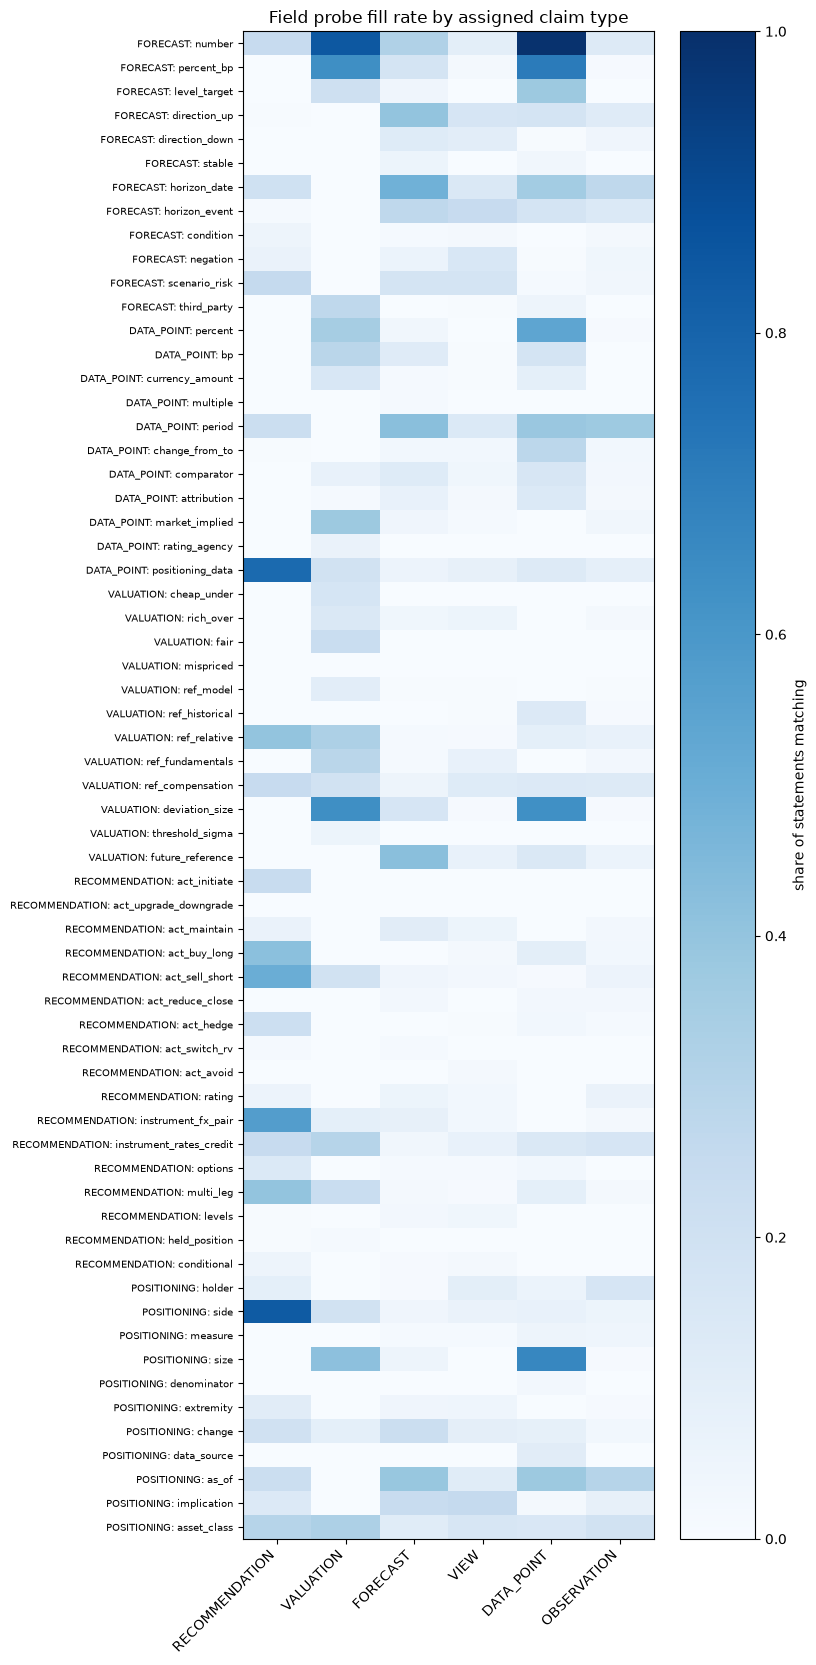

In [37]:
ALL_PROBES = {
    "FORECAST": FORECAST_PROBES,
    "DATA_POINT": DATA_POINT_PROBES,
    "VALUATION": VALUATION_PROBES,
    "RECOMMENDATION": RECOMMENDATION_PROBES,
    "POSITIONING": POSITIONING_FIELDS,
}
matrix = pd.concat(
    {owner: probe(claims, patterns).groupby(claims["claim_type"]).mean().T for owner, patterns in ALL_PROBES.items()},
    names=["probe set", "field"],
).reindex(columns=TYPES)

fig, ax = plt.subplots(figsize=(8, 0.25 * len(matrix) + 1))
im = ax.imshow(matrix.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrix)), [f"{owner}: {field}" for owner, field in matrix.index], fontsize=7)
fig.colorbar(im, ax=ax, label="share of statements matching")
ax.set_title("Field probe fill rate by assigned claim type")
plt.tight_layout()
matrix.round(2)

### Observations

- **Numbers do not separate VALUATION from DATA_POINT.** The `number`, `percent`, `size` and `deviation_size` probes fire for both (number: 0.84 vs 0.99). What separates them is the reference: `fair`, `cheap_under` and `ref_fundamentals` fire only on VALUATION.
- **Time is generic, not a type marker.** `horizon_date` and `period` fire for FORECAST (0.48), DATA_POINT (0.36–0.39) and OBSERVATION (0.27–0.37). `temporal` belongs on every type as a shared field.
- **Direction is FORECAST's discriminating payload.** `direction_up` fires at 0.40 for FORECAST vs 0.17 for VIEW.
- **Trade vocabulary equals positioning vocabulary.** `positioning_data` (0.78) and `side` (0.83) fire mainly on RECOMMENDATION. A POSITIONING type must be separated from RECOMMENDATION by **holder**, not by vocabulary.
- **VIEW has no field above 0.25.** It is defined by absence, which is consistent with VIEW being the residual hub of the confusion in §1.

### Schema notes

| Type | Keep / merge / split | Required fields | Optional fields | Open boundary |
|---|---|---|---|---|
| FORECAST | | | | |
| DATA_POINT | | | | |
| VALUATION | | | | |
| RECOMMENDATION | | | | |
| POSITIONING | | | | |